# 3-servo: load

Hang a printed arm with a known mass from the horn, the shaft horizontal, and use gravity as the load. The arm is a pendulum, so its torque on the shaft is known at every angle, and the servo lifts it, holds it, lets it fall and steps against it. This notebook reads Kt through the gears and the train's efficiency at stall, the friction the train holds against gravity, the deadband of a constant-duty hold, the lift at speed and the fall that back-drives the train, the step response under load, the stall current per duty and the pot's behavior under a held torque.

## Purpose

The later stages need the servo under a load, not only free. The free stages measured the motor's constants on this servo and the train's drag at speed. A load adds the train's torque transfer and its friction under load, and those set the hold, the stall fault and the position loop's deadband.

- Kt through the gears. The output torque per amp of winding current at a stall, per direction, against the lossless $K_e N$, with $K_e$ the motor's back-EMF constant and $N$ the gear ratio.
- Static friction. The torque the back-driven train holds against gravity with the bridge open, and the torque at which a fall starts.
- The deadband. How far the duty moves from a held value before the arm moves.
- The lift and the fall. The speed lost to the load, how much of it the winding's resistance explains, and whether the train back-drives the motor with no slip.
- The stall current per duty. The design line a stall fault and a current ceiling read, and how far a hold warms the winding.
- The pot under load. Whether a held torque moves the pot's reading with the output still.

## Procedure

The procedure is the README's `load` section, sitting `servo-load-1`, run by `uv run python -m oscnb.sitting servo-load` with `stages/3-servo/load/plan.py`, whose constants set every duty, hold and window. The rig lies on its side with the shaft horizontal. The printed load mount sits on the horn with the coin block on its beam and the quarters in the outer cup pair. The board runs the experiment image on the DPS, so every drive is open loop. Four blocks ran in one sitting.

- `bottom`. The arm hung by hand and read, then a short lift each way and a coast with the bridge open, three times a side.
- `ladder`. A duty held from the bottom, stepped up each side until the rest passed the plan's top, then three duties approached from above.
- `lift`. Three duties driven from the bottom for a fixed window each, then a coast with the fall streamed, twice each way.
- `steps`. A ladder duty held at three angles a side, a step up or down, then back.

The optional `push` block did not run in this sitting, so the pot under a pure side load is left to a later sitting (section 9).

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`. The blocks are `load/bottom-1` (`bottom.csv`, `drops/K`), `load/ladder-1` (`ladder.csv`, `ladder/K`), `load/lift-1` (`cycles.csv`, `cycles/K`) and `load/steps-1` (`chains.csv`, `chains/K`). The sitting's manifest is `sittings/servo-load-1.csv`. Each sweep folder holds `sweep.csv`, one row per control tick, and `meta.json`, whose sense block is checked against the board's registry entry on load.

The libraries, then the pair and its folders. The rig's spec imports the CAD package, and the mount's centroid comes from its built mesh. A fresh checkout needs `uv sync --group cad --group dev`, then `uv run --group cad python -m rigs.servorig` to write `rigs/servorig/build/`, and then runs the notebook under `uv run --group cad`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import trimesh
from scipy.constants import g as G_N_PER_KG
from scipy.signal import savgol_filter

from oscnb import boards, figures, results, scales, servos, sitting, tel
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

sys.path.insert(0, str(results.ROOT))   # the rigs package sits at the root
from rigs.servorig.rig import Spec      # noqa: E402, needs the cad group

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, limits
BOARD = boards.BOARDS[boards.DEFAULT]   # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD.key}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
DATA = PAIR_DIR / "load"                # the four blocks of the sitting
MANIFEST = PAIR_DIR / "sittings" / "servo-load-1.csv"
FS = BOARD.tick_hz                      # rows per second, the control tick
ARR = BOARD.pwm_arr                     # timer ticks per PWM period
GEAR = SERVO.gear_ratio                 # motor revs per output rev, teeth
print(SERVO.key, "on", BOARD.key, "from", results.rel(DATA))
print(f"gear {GEAR:.4f}:1, {FS} rows/s, PWM period {ARR} ticks")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/load
gear 308.0533:1, 20000 rows/s, PWM period 1200 ticks


## 1. The setup

### Earlier results carried in

The stage 1 scales turn counts into amps and volts. The ladder gives Ke, which in SI units is also Kt. The resistance result gives the locked resistance, the as-read and construction C stall lines, the crest term $g$ confirmed by the meter, the bridge's edge lag and the heating time constant. Bridge-states gives the brake loop's resistance, run-up the rotor and train's inertia at the motor, the free steps their current and speed per percent, and the pot table the counts-to-degrees table and the hand-rock swing. mg90-b's Ke stands as the type value.

In [3]:
SC = scales.load(BOARD)                 # stage 1: counts to amps and volts
BRIDGE = results.read("1-board", "bridge-states", pair=BOARD.key)
LADDER = results.read("3-servo", "ladder", pair=PAIR)
RES = results.read("3-servo", "resistance", pair=PAIR)
RUNUP = results.read("3-servo", "run-up", pair=PAIR)
FREE_STEPS = results.read("3-servo", "steps", pair=PAIR)
POT = results.read("3-servo", "pot-table", pair=PAIR)
TYPE = results.read("2-motor", "bemf-coast", pair="mg90-b")
SC.describe()

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end


In [4]:
KE = LADDER["ke_v_s_per_rad"]["value"]       # V s/rad, = Kt in N m/A
KT_TYPE = TYPE["ke_v_s_per_rad"]["value"]    # mg90-b, the type's Kt
R_LOCKED = RES["r_term_ohm"]["value"]        # ohm, locked 100 % laps
R_STOP_A = RES["r_stop_ohm"]["value"]        # ohm, as read at the stops
V0_STOP_A = RES["v0_stop_v"]["value"]        # V, that line's offset
R_C = RES["r_rails_c_ohm"]["value"]          # ohm, construction C
V0_C = RES["v0_rails_c_v"]["value"]          # V, construction C
G_S = RES["meter_g_ms"]["value"] / 1e3       # S, the crest term, meter
EDGE = RES["edge_ticks_measured_5v"]["value"]  # ticks, edge lag at 5 V
R_BRAKE = BRIDGE["low_side_loop_ohm"]["value"]  # ohm, the brake loop
TAU_HEAT_S = RES["meter_heating_tau_s"]["value"]  # s, winding heating
T0_C = RES["board_ntc_c"]["value"]           # C, the resistance rest NTC
J_MOTOR = RUNUP["j_kg_m2"]["value"]          # kg m2, rotor + train
K_I_FREE = FREE_STEPS["k_i_settled_ma_per_pct"]["value"]   # mA per %
K_W_FREE = FREE_STEPS["k_w_rev_s_per_pct"]["value"]        # rev/s per %
TAU_M_FREE = FREE_STEPS["tau_m_ms"]["value"]               # ms
LASH_HAND = POT["lash_hand_deg"]["value"]    # deg, the pot-table hand rock
KT_IDEAL = KE * GEAR * 1e3                   # mN m/A at the output, no loss
ALPHA_CU = 0.0039                            # 1/C, copper, the README
SERVO_ENDS = (82, 3792)   # counts, the free ends read by hand at each
#                           stop, the resistance notebook's SERVO_ENDS
print(f"Ke {KE * 1e3:.4f} mV s/rad (type mg90-b {KT_TYPE * 1e3:.4f}), "
      f"Ke x N {KT_IDEAL:.1f} mN m/A")
print(f"R locked {R_LOCKED:.3f} ohm; as read at the stops {R_STOP_A:.3f} "
      f"ohm, V0 {V0_STOP_A * 1e3:+.0f} mV; C {R_C:.3f} ohm, V0 "
      f"{V0_C * 1e3:+.0f} mV")
print(f"g {G_S * 1e3:.3f} mS, edge {EDGE:.2f} ticks, brake loop "
      f"{R_BRAKE:.3f} ohm, heating tau {TAU_HEAT_S:.2f} s, T0 {T0_C:.2f} C")
print(f"J {J_MOTOR:.3e} kg m2; free steps k_i {K_I_FREE:.2f} mA/%, k_w "
      f"{K_W_FREE:.2f} rev/s per %, tau_m {TAU_M_FREE:.1f} ms; lash_hand "
      f"{LASH_HAND:.2f} deg")

Ke 1.1591 mV s/rad (type mg90-b 1.1684), Ke x N 357.1 mN m/A
R locked 4.219 ohm; as read at the stops 4.377 ohm, V0 +11 mV; C 4.177 ohm, V0 +31 mV
g 4.746 mS, edge 25.05 ticks, brake loop 0.301 ohm, heating tau 3.39 s, T0 26.26 C
J 6.433e-09 kg m2; free steps k_i 1.08 mA/%, k_w 5.64 rev/s per %, tau_m 20.9 ms; lash_hand 1.24 deg


### The arm and its torque

Gravity's torque on the shaft is

$$\tau = m g L \sin\theta$$

with $\tau$ ("tau") the torque, $m$ the mass, $g$ the acceleration of gravity, $L$ the mass's lever from the axis and $\theta$ ("theta") the arm's angle from the bottom. Each part of the arm adds its own $m g L$ at horizontal. The coins come from the rig's CAD spec and the mint's spec, the rest of the arm from a kitchen scale, and the load mount's lever from its mesh.

In [5]:
RIG = Spec()                            # the rig's CAD spec
N_COINS = 22                            # sitting 1, 11 in each outer cup
COINS_G = N_COINS * RIG.unit_g          # g, mint spec, not weighed alone
COIN_TOL = 0.01                         # the coins' own mass, +/- 1 %
COINS_R_MM = RIG.stack_radii()[1]       # mm, the axis to the outer pair
# both weighed by hand on a kitchen scale, 1 g steps
ARM_ALL_G = 166.0     # g, the whole arm with the 22 quarters and screws
BLOCK_ALL_G = 153.0   # g, block + lid + the quarters + the three screws
SCALE_STEP_G = 1.0    # g, the kitchen scale's resolution
BLOCK_G = BLOCK_ALL_G - COINS_G         # g, block + lid + three screws
MOUNT_G = ARM_ALL_G - BLOCK_ALL_G       # g, the load mount, hub + beam
BLOCK_R_MM = RIG.arm_r                  # mm, the axis to the cups' center
print(f"coins {N_COINS} x {RIG.unit_g} g = {COINS_G:.2f} g at "
      f"{COINS_R_MM:.2f} mm; block + lid + screws {BLOCK_G:.1f} g at "
      f"{BLOCK_R_MM:.1f} mm; mount {MOUNT_G:.1f} g")
print(f"weighed: arm {ARM_ALL_G:.0f} g, block {BLOCK_ALL_G:.0f} g, steps "
      f"of {SCALE_STEP_G:.0f} g; coins +/- {COIN_TOL * 100:.0f} %; the "
      f"inner cup pair at {RIG.stack_radii()[0]:.2f} mm")

coins 22 x 5.67 g = 124.74 g at 68.43 mm; block + lid + screws 28.3 g at 55.0 mm; mount 13.0 g
weighed: arm 166 g, block 153 g, steps of 1 g; coins +/- 1 %; the inner cup pair at 41.57 mm


In [6]:
STL = results.ROOT / "rigs/servorig/build/servorig_load_mount.stl"
mesh = trimesh.load(STL)                # hub + beam in its print pose
MOUNT_CM3 = mesh.volume / 1e3           # cm3, the solid's volume
MOUNT_R_MM = abs(mesh.center_mass[1])   # mm, the beam runs along -Y
print(f"{results.rel(STL)}: {MOUNT_CM3:.2f} cm3, centroid "
      f"{MOUNT_R_MM:.1f} mm from the hub's axis")

rigs/servorig/build/servorig_load_mount.stl: 20.05 cm3, centroid 14.1 mm from the hub's axis


The coins are 22 quarters at the US mint's 5.670 g, not weighed apart from the block, so their mass carries the mint's own spread of about 1 %. Their lever is the outer cup pair's radius in the rig's CAD spec. The arm was weighed by hand on a kitchen scale in 1 g steps, the whole arm with its quarters and screws at 166 g and the coin block with its lid, the quarters and its three screws at 153 g. Less the quarters, that leaves the block, the lid and the screws, taken at the cups' center, and the load mount, the hub and beam, taken at its mesh centroid.

In [7]:
def torque_mn_m(mass_g, r_mm):
    """Weight times lever at horizontal: g and mm in, mN m out."""
    return mass_g / 1e3 * G_N_PER_KG * r_mm


TAU_COINS = torque_mn_m(COINS_G, COINS_R_MM)
TAU_ARM = torque_mn_m(BLOCK_G, BLOCK_R_MM) + torque_mn_m(MOUNT_G,
                                                          MOUNT_R_MM)
TAU_H = TAU_COINS + TAU_ARM             # mN m at horizontal, all of it
SCALE = TAU_H / TAU_COINS               # absolute over coins-scale
# one gram of the scale's step moved between the block and the mount
SPLIT = torque_mn_m(SCALE_STEP_G, BLOCK_R_MM - MOUNT_R_MM)
SCALE_LO = (TAU_COINS * (1 - COIN_TOL) + TAU_ARM - SPLIT) / TAU_COINS
SCALE_HI = (TAU_COINS * (1 + COIN_TOL) + TAU_ARM + SPLIT) / TAU_COINS
print(f"coins {TAU_COINS:.2f} + arm {TAU_ARM:.2f} = {TAU_H:.2f} mN m at "
      f"horizontal; factor {SCALE:.4f} ({SCALE_LO:.4f} to {SCALE_HI:.4f})")
print(f"1 g moved between block and mount: {SPLIT:.2f} mN m, "
      f"{SPLIT / TAU_ARM * 100:.1f} % of the arm's term, "
      f"{SPLIT / TAU_H * 100:.2f} % of the total; the coins' 1 %: "
      f"{TAU_COINS * COIN_TOL:.2f} mN m")
print(f"the scale's {SCALE_STEP_G:.0f} g is {SCALE_STEP_G / MOUNT_G * 100:.0f}"
      f" % of the mount's {MOUNT_G:.0f} g")


def gravity_coins(theta):
    """Gravity's torque at theta deg from the bottom, the coins alone."""
    return TAU_COINS * np.sin(np.radians(np.abs(theta)))

coins 83.71 + arm 17.04 = 100.75 mN m at horizontal; factor 1.2035 (1.1887 to 1.2183)
1 g moved between block and mount: 0.40 mN m, 2.4 % of the arm's term, 0.40 % of the total; the coins' 1 %: 0.84 mN m
the scale's 1 g is 8 % of the mount's 13 g


The arm adds 17.04 mN m at horizontal to the coins' 83.71, 100.75 mN m in all, a factor of 1.2035 on every torque the coins alone give. Every torque below is absolute, the coins' share times this factor, and the coins' share is printed beside it where it helps a comparison.

The factor's own error is small. The coins' 1 % is 0.84 mN m. The scale's 1 g step is 8 % of the mount's 13 g, and one gram moved between the block and the mount changes the arm's term by 0.40 mN m, 2.4 % of the arm's term and 0.40 % of the total. The three screws weighed with the block sit at the hub, so taking them at the cups' radius overcounts their lever by about that same gram's worth. Together these bound the factor to 1.1887 to 1.2183.

### The pot table

Angles go through the pot table, not the registry's nominal scale, with the end rows' slope carried on past its ends.

In [8]:
TABLE = pd.read_csv(results.path("3-servo", "pot-table", pair=PAIR)
                    .with_suffix(".table.csv"))
TC = TABLE["counts"].to_numpy()         # the table's counts, rising
TA = TABLE["angle_deg"].to_numpy()      # the tag degrees at each
S_LO = (TA[1] - TA[0]) / (TC[1] - TC[0])      # deg per count, low end
S_HI = (TA[-1] - TA[-2]) / (TC[-1] - TC[-2])  # deg per count, high end


def angle_of(counts):
    """Tag degrees of a pot count; past the ends the end slope runs on."""
    c = np.asarray(counts, float)
    a = np.interp(c, TC, TA)
    a = np.where(c < TC[0], TA[0] + (c - TC[0]) * S_LO, a)
    return np.where(c > TC[-1], TA[-1] + (c - TC[-1]) * S_HI, a)


def outside_table(counts):
    c = np.asarray(counts, float)
    return (c < TC[0]) | (c > TC[-1])


def theta_deg(counts, bottom):
    """Degrees from the bottom: + up the side of higher counts."""
    return angle_of(counts) - angle_of(bottom)


print(f"table {TC[0]:.0f} to {TC[-1]:.0f} counts, {TA[-1] - TA[0]:.0f} "
      f"deg; end slopes {1 / S_LO:.1f} and {1 / S_HI:.1f} counts/deg; the "
      f"registry's nominal {SERVO.counts_per_deg_nominal} counts/deg")

table 582 to 3188 counts, 134 deg; end slopes 25.1 and 27.0 counts/deg; the registry's nominal 19.8 counts/deg


The registry's nominal scale is 19.8 counts per degree. The table covers 582 to 3188 counts, 134 degrees, and past its ends the end rows' slope carries on, 25.1 counts per degree at the low end and 27.0 at the high. The top rungs of each side rest outside it (section 4).

### One sweep with the scales applied

A sweep's current is the crest sample over its own torque-off zero, the stage 1 in-drive offset taken out on driven rows. The volts are the crest tap difference. With the bridge open the same difference is the motor's EMF over its own zero. Partial-duty numbers use construction C, as the resistance result decided it. The winding current is $i_w = i_\mathrm{crest} - g (1 - D) V_\mathrm{on}$ and the applied volts are $V_c = s V_\mathrm{on} - (1 - s) R_\mathrm{brake} i_w$, with $D$ the duty, $V_\mathrm{on}$ the crest tap volts, $R_\mathrm{brake}$ the brake loop and $s = D - 25.05 / 1200$ the window shortened by the bridge's edge lag. The pot's speed at a row is the slope of a line through the angle over a centered window.

In [9]:
def load_sweep(folder, bottom=None):
    """(rows, meta) of one sweep with the board's scales applied."""
    df, meta = tel.load(folder, board=BOARD)   # the sense block checked
    zero_i, zero_e = tel.rest_zeros(df)        # the sweep's own zeros
    df["zero_i"], df["zero_e"] = zero_i, zero_e
    driven = (df["duty_counts"] != 0).to_numpy()
    # amps over the zero, the in-drive offset out on driven rows
    df["i_a"] = np.where(driven, SC.amps(df["current_raw"], zero_i, True),
                         SC.amps(df["current_raw"], zero_i, False))
    tap = df["vmotor_a"] - df["vmotor_b"]      # the crest tap difference
    df["vdiff_v"] = SC.volts(tap, SC.terminal_offset_counts)
    df["emf_v"] = SC.volts(tap, zero_e)        # bridge open: the EMF
    df["D"] = df["duty_counts"].abs() / ARR    # the applied window share
    if bottom is not None:
        df["theta"] = theta_deg(df["pos"], bottom)
    return df, meta


def construction_c(D, v_on, i_crest):
    """(applied volts, winding current) under construction C: the edge
    lag off the window, the brake loop's drop between windows, and the
    crest term g (1 - D) V_on off the current."""
    share = D - EDGE / ARR
    c = scales.constructions(D, share, v_on, i_crest, share, share,
                             R_BRAKE, G_S)
    return c["v_c"], c["i_c"]


def pot_speed(pos, half):
    """deg/s per row: a centered line through +/- half rows of angle."""
    a = angle_of(pos)
    k = np.arange(-half, half + 1)
    out = np.full(len(a), np.nan)
    for i in range(half, len(a) - half):
        out[i] = (k * (a[i - half:i + half + 1] - a[i])).sum()
    return out / (k ** 2).sum() * FS

### The sitting's manifest

The runner's log, one row per event. Before every sweep it read `pos`, `ntc_raw` and `vbus_raw`, and those probes give the hand reading of the bottom, the board NTC through the sitting and the rail. The guards sit 100 counts inside the soft limits.

In [10]:
EVENTS = pd.read_csv(MANIFEST)
pr = EVENTS[EVENTS["event"] == "probe"]["detail"].str.extract(
    r"(.+?): pos (\d+), ntc_raw (\d+), vbus_raw (\d+)")
PROBES = pd.DataFrame({
    "t_host": EVENTS.loc[pr.index, "t_host"],
    "label": pr[0], "pos": pr[1].astype(int),
    "ntc_c": BOARD.ntc_c_beta(pr[2].astype(int)),
    "rail_v": SC.rail_v(pr[3].astype(int))})
PROBES["folder"] = PROBES["label"].str.replace(
    f"telemetry/{PAIR}/load/", "", regex=False)
HAND = int(PROBES.loc[PROBES["label"] == "hanging", "pos"].iloc[0])
guard_row = EVENTS.loc[EVENTS["event"] == "guards", "detail"].iloc[0]
GUARDS = tuple(int(x) for x in guard_row.split()[0:3:2])
SOFT = (GUARDS[0] - sitting.GUARD_INSET, GUARDS[1] + sitting.GUARD_INSET)
found = EVENTS.loc[EVENTS["event"] == "found", "detail"].iloc[0]
show(EVENTS[EVENTS["event"] != "probe"][["t_host", "event", "detail"]],
     n=None)
print(f"{len(PROBES)} probes; hanging read {HAND}; guards {GUARDS}, "
      f"soft limits {SOFT}; found: {found}")

,t_host,event,detail
0,11:08:51.595,start,"servo mg90-d, motor mg90-d, board dev-v006-2A-..."
1,11:09:01.526,prompt,"The rig on its side with the shaft horizontal,..."
2,11:09:01.526,plan,bottom
3,11:09:01.528,dataset,bottom: telemetry/mg90-d__dev-v006-2A-D/load/b...
4,11:09:14.769,dps,on at 5.25 V
5,11:09:18.726,rail,"5.0 V: reads 5.013 V, DPS 5.250 V"
6,11:12:12.881,prompt,"Hang the arm straight down by hand, the mass p..."
8,11:12:13.247,guards,414 to 3460 counts
15,11:15:20.394,found,"bottom 2007 counts, the drops rest 329.3 count..."
16,11:15:20.394,plan,ladder


76 probes; hanging read 2024; guards (414, 3460), soft limits (314, 3560); found: bottom 2007 counts, the drops rest 329.3 counts apart, hanging it read 2024


In [11]:
def probe_for(folder_rel):
    """The manifest's probe before a sweep, None if it has none."""
    hit = PROBES[PROBES["folder"] == folder_rel]
    return None if hit.empty else hit.iloc[0]

## 2. The bottom

The plan found the bottom from the drops, a 12 % lift each way and a coast. The coast was meant to drop the arm and let it swing to rest. It did not drop.

In [12]:
BOTTOM_CSV = pd.read_csv(DATA / "bottom-1/bottom.csv")
drop_rows = []
for _, r in BOTTOM_CSV.iterrows():
    df, _ = load_sweep(DATA / "bottom-1" / r["folder"])
    hold = df[df["seg"] == 1]           # the 12 % lift, 1.5 s
    coast = df[df["seg"] == 2]          # the bridge open, 3 s
    drop_rows.append({
        "k": r["k"], "side": r["side"],
        "hold_rest": hold["pos"].iloc[-2000:].median(),   # last 100 ms
        "coast_first": coast["pos"].iloc[200:2200].median(),  # 10-110 ms
        "coast_last": coast["pos"].iloc[-10000:].median(),    # last 0.5 s
        "emf_peak_v": coast["emf_v"].iloc[200:].abs().max(),
        "i_hold_a": hold["i_a"].iloc[-2000:].mean()})
DROPS = pd.DataFrame(drop_rows)
DROPS["coast_move"] = DROPS["coast_last"] - DROPS["coast_first"]
show(DROPS, n=None)
print(f"largest move through the coast {DROPS['coast_move'].abs().max():.0f}"
      f" counts; peak EMF {DROPS['emf_peak_v'].max():.3f} V")

,k,side,hold_rest,coast_first,coast_last,emf_peak_v,i_hold_a,coast_move
0,0,1,2169.000,2165.000,2165.000,0.048,0.136,0.000
1,1,1,2180.000,2178.000,2177.000,0.048,0.138,-1.000
2,2,1,2175.000,2174.000,2173.000,0.052,0.137,-1.000
3,3,-1,1851.000,1852.000,1853.000,0.040,0.137,1.000
4,4,-1,1832.000,1833.000,1834.000,0.044,0.136,1.000
5,5,-1,1835.000,1838.000,1838.000,0.068,0.136,0.000


largest move through the coast 1 counts; peak EMF 0.068 V


In [13]:
up12 = DROPS[DROPS["side"] == 1]["hold_rest"].to_numpy()
dn12 = DROPS[DROPS["side"] == -1]["hold_rest"].to_numpy()
COUNT_MID = (up12.mean() + dn12.mean()) / 2      # the plan's midpoint
# the degree midpoint: the count whose table angle is the two sides' mean
mid_angle = (angle_of(up12).mean() + angle_of(dn12).mean()) / 2
grid = np.arange(1800, 2300)
DEG_MID = int(grid[np.argmin(np.abs(angle_of(grid) - mid_angle))])
PLAN_BOTTOM = int(round(COUNT_MID))
for name, b in (("count midpoint", PLAN_BOTTOM), ("degree midpoint",
                                                 DEG_MID), ("hand", HAND)):
    print(f"{name:16s} {b} counts: 12 % rests at "
          f"{theta_deg(up12, b).mean():+.2f} (sd {up12.std(ddof=1):.1f} "
          f"counts) and {theta_deg(dn12, b).mean():+.2f} deg (sd "
          f"{dn12.std(ddof=1):.1f} counts)")
print(f"hand against the degree midpoint {theta_deg(HAND, DEG_MID):+.2f} "
      f"deg, the count midpoint {theta_deg(PLAN_BOTTOM, DEG_MID):+.2f} deg")

count midpoint   2007 counts: 12 % rests at +10.27 (sd 5.5 counts) and -8.76 deg (sd 10.2 counts)
degree midpoint  2021 counts: 12 % rests at +9.52 (sd 5.5 counts) and -9.51 deg (sd 10.2 counts)
hand             2024 counts: 12 % rests at +9.34 (sd 5.5 counts) and -9.69 deg (sd 10.2 counts)
hand against the degree midpoint +0.18 deg, the count midpoint -0.75 deg


The 12 % holds left the arm about 9.5 degrees either side, and the 3 s coasts that followed moved it by at most 1 count, with a peak EMF of 0.068 V. Gravity's torque at 9.5 degrees sits inside the train's static band (section 3), so the block measured the two sides' 12 % torque rests, not a hang.

The plan took the count midpoint of those rests, 2007. Through the table the two rests sit at +10.27 and -8.76 degrees from 2007, and at +9.52 and -9.51 degrees from 2021. In degrees the midpoint is 2021 counts, 0.18 degrees from the hand reading of 2024. The count midpoint sits 0.75 degrees off because the pot's local scale differs on the two sides of the bottom.

In [14]:
BOTTOM = DEG_MID                        # counts, the bottom of record
BOTTOM_LO, BOTTOM_HI = sorted((PLAN_BOTTOM, HAND))   # the bracket
for name, lo, hi in (("up", 0, 10), ("down", -5, 0)):
    a0 = angle_of(BOTTOM)
    m = (TA >= a0 + lo) & (TA <= a0 + hi)
    s = TABLE.loc[m, "local_scale_counts_per_deg"]
    print(f"{name} side, {lo:+d} to {hi:+d} deg: the table's local scale "
          f"{s.min():.1f} to {s.max():.1f} counts/deg")
print(f"bottom {BOTTOM} counts, bracket {BOTTOM_LO} to {BOTTOM_HI}")

up side, +0 to +10 deg: the table's local scale 14.6 to 17.5 counts/deg
down side, -5 to +0 deg: the table's local scale 19.5 to 23.3 counts/deg
bottom 2021 counts, bracket 2007 to 2024


The bottom of record is 2021, the 12 % rests' degree midpoint. It assumes the two sides' torque at 12 % is the same, and the drops' 12 % currents read 0.136 to 0.138 A on both sides. 2007, the plan's count midpoint, and 2024, the hand reading, bracket it. Section 4 shows what moves with the bottom.

The table's local scale near the bottom is 14.6 to 17.5 counts per degree over the first 10 degrees of the up side and 19.5 to 23.3 over the first 5 degrees of the down side. That difference is why the count midpoint and the degree midpoint part.

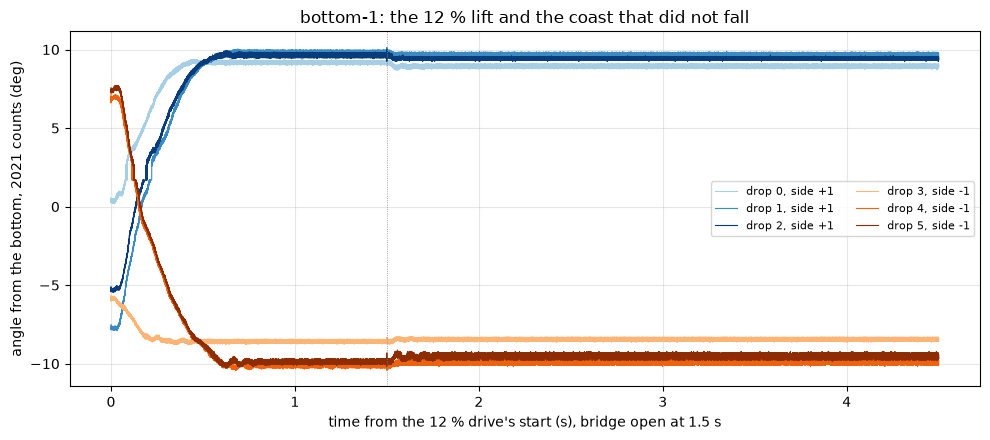

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for (_, r), color in zip(BOTTOM_CSV.iterrows(),
                         figures.shades("Blues", 3).tolist()
                         + figures.shades("Oranges", 3).tolist()):
    df, _ = load_sweep(DATA / "bottom-1" / r["folder"], BOTTOM)
    d = df[df["seg"] > 0]
    t = np.arange(len(d)) / FS
    ax.plot(t, d["theta"], lw=0.8, color=color,
            label=f"drop {r['k']}, side {r['side']:+d}")
ax.axvline(1.5, **figures.EDGE_STYLE)
figures.label(ax, x="time from the 12 % drive's start (s), bridge open "
              "at 1.5 s", y=f"angle from the bottom, {BOTTOM} counts (deg)",
              title="bottom-1: the 12 % lift and the coast that did not "
              "fall")
ax.legend(fontsize=8, ncol=2)
figures.finish(fig)

What you are looking at. The six drops' angle from the bottom against time, the 12 % drive to 1.5 s, then the coast. Each trace stays flat after the bridge opens. Nothing fell.

## 3. The static friction

Three readings of the friction that holds the back-driven train still against gravity, the holds that did not fall, the start of each fall and where the swings died.

In [16]:
LADDER_CSV = pd.read_csv(DATA / "ladder-1/ladder.csv")
SEEK = LADDER_CSV["first_pos"].to_numpy()   # where each rung started


def hold_report(name, counts):
    """Angle and gravity's torque at a rest, and the motor's share."""
    th = np.abs(theta_deg(counts, BOTTOM))
    tau = gravity_coins(th)             # mN m, coins-scale
    print(f"{name:24s} {th.mean():5.2f} deg (sd {th.std(ddof=1):.2f}, n "
          f"{len(th)}): {tau.mean():5.2f} mN m coins-scale, "
          f"{tau.mean() * SCALE:5.2f} absolute = "
          f"{tau.mean() * SCALE / GEAR * 1e3:4.1f} uN m, "
          f"{tau.mean() * SCALE / GEAR / KE:4.1f} mA at the motor")
    return th, tau * SCALE


TH_UP, HELD_UP = hold_report("12 % rest, up side", up12)
TH_DN, HELD_DN = hold_report("12 % rest, down side", dn12)
hold_report("seek rests, up side", SEEK[SEEK > BOTTOM])
hold_report("seek rests, down side", SEEK[SEEK < BOTTOM])
HELD_LO = min(HELD_UP.mean(), HELD_DN.mean())   # the sides' means
print(f"lower bound on the held static friction {HELD_LO:.1f} mN m")
SEEK_MAX = np.abs(theta_deg(SEEK, BOTTOM)).max()
print(f"seek rests {theta_deg(SEEK.min(), BOTTOM):+.1f} to "
      f"{theta_deg(SEEK.max(), BOTTOM):+.1f} deg, the farthest "
      f"{gravity_coins(SEEK_MAX) * SCALE:.1f} mN m absolute")

12 % rest, up side        9.52 deg (sd 0.33, n 3): 13.85 mN m coins-scale, 16.66 absolute = 54.1 uN m, 46.7 mA at the motor
12 % rest, down side      9.51 deg (sd 0.83, n 3): 13.83 mN m coins-scale, 16.65 absolute = 54.0 uN m, 46.6 mA at the motor
seek rests, up side       6.44 deg (sd 2.68, n 17):  9.37 mN m coins-scale, 11.28 absolute = 36.6 uN m, 31.6 mA at the motor
seek rests, down side     6.00 deg (sd 2.77, n 28):  8.74 mN m coins-scale, 10.51 absolute = 34.1 uN m, 29.4 mA at the motor
lower bound on the held static friction 16.6 mN m
seek rests -12.5 to +13.2 deg, the farthest 23.0 mN m absolute


The 12 % rests held through their 3 s coast at 9.52 and 9.51 degrees, 6 of 6. Gravity there is 16.66 and 16.65 mN m at the output, so the train's static friction, back-driven with the bridge open, holds at least 16.6 mN m. That is a lower bound. At the motor it is 54 uN m, 46.7 mA at Ke. The seek to the start of each ladder rung left the arm anywhere from -12.5 to +13.2 degrees, and the farthest of those rests held 23.0 mN m.

In [17]:
J_REFL = J_MOTOR * GEAR ** 2            # kg m2, rotor + train at the output
J_COINS = COINS_G / 1e3 * (COINS_R_MM / 1e3) ** 2   # kg m2, point masses
J_OUT = J_REFL + J_COINS                # coins-scale, as the note takes it
J_ARM = (BLOCK_G * BLOCK_R_MM ** 2 + MOUNT_G * MOUNT_R_MM ** 2) / 1e9
J_TOTAL = J_OUT + J_ARM                 # kg m2, the arm as point masses
print(f"at the output: rotor + train {J_REFL * 1e3:.3f} g m2, coins "
      f"{J_COINS * 1e3:.3f}, arm {J_ARM * 1e3:.3f}, sum "
      f"{J_TOTAL * 1e3:.3f} g m2 (coins-scale {J_OUT * 1e3:.3f})")

at the output: rotor + train 0.610 g m2, coins 0.584, arm 0.088, sum 1.283 g m2 (coins-scale 1.195)


In [18]:
CYCLES = pd.read_csv(DATA / "lift-1/cycles.csv")
FALL_ROWS, DRIVE_ROWS = {}, {}
for _, r in CYCLES.iterrows():
    df, _ = load_sweep(DATA / "lift-1" / r["folder"], BOTTOM)
    s1 = df[df["seg"] == 1].reset_index(drop=True)   # the drive
    s2 = df[df["seg"] == 2].reset_index(drop=True)   # the 3 s coast
    DRIVE_ROWS[r["k"]] = tel.drive_rows(s1).reset_index(drop=True)
    # the stream opens before the bridge does: from 2 rows after
    z = int(np.flatnonzero(s2["duty_counts"].to_numpy() == 0)[0]) + 2
    FALL_ROWS[r["k"]] = (s2, s2.iloc[z:].reset_index(drop=True))
print(f"{len(CYCLES)} cycles: drives of {sorted(CYCLES['spin_ms'].unique())}"
      f" ms, each followed by a 3 s coast")

12 cycles: drives of [np.int64(500), np.int64(700), np.int64(1000)] ms, each followed by a 3 s coast


In [19]:
fall_rest = []
for _, r in CYCLES.iterrows():
    s2, f = FALL_ROWS[r["k"]]
    end = s2["pos"].iloc[-10000:].median()   # the coast's last 0.5 s
    # the pot's last move of more than 3 counts off its end rest
    moving = np.flatnonzero(np.abs(s2["pos"].to_numpy() - end) > 3)
    fall_rest.append({
        "k": r["k"], "side": r["side"], "duty_pct": r["duty_pct"],
        "repeat": r["repeat"], "fall_end_pos": end,
        "end_deg": theta_deg(end, BOTTOM),
        "t_still_s": (moving[-1] + 1) / FS if len(moving) else 0.0})
FALL_REST = pd.DataFrame(fall_rest)
show(FALL_REST, n=None)
SWING = FALL_REST["end_deg"].abs()
print(f"swing rests {SWING.min():.1f} to {SWING.max():.1f} deg from the "
      f"bottom, {gravity_coins(SWING).min() * SCALE:.1f} to "
      f"{gravity_coins(SWING).max() * SCALE:.1f} mN m absolute")

,k,side,duty_pct,repeat,fall_end_pos,end_deg,t_still_s
0,0,1,20,0,2092.000,4.643,2.786
1,1,1,20,1,2104.000,5.348,2.331
2,2,1,30,0,2018.000,-0.161,2.946
3,3,1,30,1,2015.000,-0.323,2.989
4,4,1,40,0,1922.000,-4.577,2.998
5,5,1,40,1,1914.000,-4.937,0.741
6,6,-1,20,0,1895.000,-5.966,0.534
7,7,-1,20,1,1912.000,-5.044,0.579
8,8,-1,30,0,2047.000,1.686,2.984
9,9,-1,30,1,2059.000,2.506,3.000


swing rests 0.2 to 7.4 deg from the bottom, 0.3 to 13.0 mN m absolute


In [20]:
RELEASE_S = 0.08                        # s, the fall's start fitted
rel = []
for _, r in CYCLES.iterrows():
    _, f = FALL_ROWS[r["k"]]
    tf = np.arange(len(f)) / FS
    th = np.asarray(theta_deg(f["pos"], BOTTOM))   # signed
    m0 = tf < RELEASE_S
    # theta = theta0 + alpha t^2 / 2 from rest: twice the square term
    alpha = 2 * np.polyfit(tf[m0], np.radians(th[m0]), 2)[0]   # rad/s2
    sin0 = np.sin(np.radians(th[0]))   # gravity pulls to the bottom
    rel.append({"k": r["k"], "side": r["side"], "duty_pct": r["duty_pct"],
                "theta0": th[0], "alpha_rad_s2": alpha,
                "release_coins": abs(-TAU_COINS * sin0
                                     - J_OUT * alpha * 1e3),
                "tau_g_mn_m": -TAU_H * sin0,              # absolute
                "j_alpha_mn_m": J_TOTAL * alpha * 1e3,    # absolute
                "release_mn_m": abs(-TAU_H * sin0
                                    - J_TOTAL * alpha * 1e3)})
RELEASE = pd.DataFrame(rel)
show(RELEASE, n=None)
rc, ra = RELEASE["release_coins"], RELEASE["release_mn_m"]
print(f"release friction {rc.mean():.1f} +/- {rc.std(ddof=1):.1f} mN m "
      f"coins-scale; absolute with the arm's weight and inertia "
      f"{ra.mean():.1f} +/- {ra.std(ddof=1):.1f} (n {len(rc)})")
for side in (1, -1):
    x = RELEASE[RELEASE["side"] == side]["release_mn_m"]
    print(f"   side {side:+d}: {x.min():.1f} to {x.max():.1f} mN m")
print(f"fit over the first {RELEASE_S * 1e3:.0f} ms; in motor units "
      f"{ra.mean() / GEAR * 1e3:.0f} uN m, "
      f"{ra.mean() / GEAR / KE:.0f} mA at Ke")

,k,side,duty_pct,theta0,alpha_rad_s2,release_coins,tau_g_mn_m,j_alpha_mn_m,release_mn_m
0,0,1,20,20.578,-6.154,22.071,-35.411,-7.893,27.518
1,1,1,20,20.578,-1.197,27.993,-35.411,-1.535,33.876
2,2,1,30,36.433,-17.913,28.314,-59.831,-22.976,36.855
3,3,1,30,36.389,-14.598,32.223,-59.769,-18.724,41.045
4,4,1,40,48.305,-32.122,24.132,-75.227,-41.202,34.025
5,5,1,40,49.321,-31.074,26.361,-76.404,-39.858,36.546
6,6,-1,20,-21.120,4.687,24.563,36.301,6.012,30.290
7,7,-1,20,-22.967,8.990,21.924,39.312,11.531,27.780
8,8,-1,30,-38.800,27.304,19.835,63.129,35.022,28.107
9,9,-1,30,-39.122,26.590,21.054,63.569,34.106,29.463


release friction 25.2 +/- 3.6 mN m coins-scale; absolute with the arm's weight and inertia 33.4 +/- 4.7 (n 12)
   side +1: 27.5 to 41.0 mN m
   side -1: 27.8 to 39.1 mN m
fit over the first 80 ms; in motor units 108 uN m, 94 mA at Ke


The start of each fall. Over the first 80 ms of a coast the arm starts from rest, so its angle is $\theta_0 + \alpha t^2 / 2$, and a quadratic gives the acceleration $\alpha$ ("alpha"). Gravity less $J \alpha$ is the friction the fall starts against. Gravity is the absolute torque, the coins and the arm. $J$ is the inertia at the output, the coins at their radius, the block and lid at the cups' center and the mount at its centroid as point masses, 0.088 g m2 for the arm, and the rotor and train reflected through $N^2$, 1.283 g m2 in all. The beam's own spread about its centroid is left out, a few percent of the arm's term. The coins-scale reading, the coins' gravity and inertia alone, is printed beside it.

The swings died 0.2 to 7.4 degrees from the bottom, all inside the 9.5 degree band of the holds, where gravity is 0.3 to 13.0 mN m.

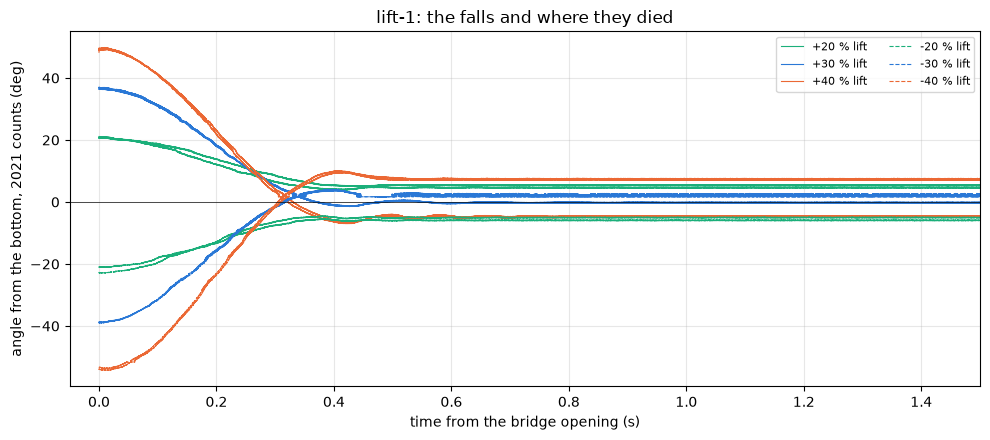

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = {20: GREEN, 30: BLUE, 40: ORANGE}
for _, r in CYCLES.iterrows():
    _, f = FALL_ROWS[r["k"]]
    t = np.arange(len(f)) / FS
    ax.plot(t, theta_deg(f["pos"], BOTTOM), lw=0.8,
            color=colors[r["duty_pct"]], ls="-" if r["side"] > 0 else "--",
            label=(f"{r['side'] * r['duty_pct']:+d} % lift"
                   if r["repeat"] == 0 else None))
ax.axhline(0, color=INK, lw=0.5)
ax.set_xlim(-0.05, 1.5)
figures.label(ax, x="time from the bridge opening (s)",
              y=f"angle from the bottom, {BOTTOM} counts (deg)",
              title="lift-1: the falls and where they died")
ax.legend(fontsize=8, ncol=2)
figures.finish(fig)

What you are looking at. The angle from the bottom through each coast after a lift, the up side solid and the down side dashed, one color per lift duty. The release friction reads 33.4 +/- 4.7 mN m (n 12), 27.5 to 41.0 on the up side and 27.8 to 39.1 on the down side, the two sides inside each other's scatter. At the motor that is 108 uN m, 94 mA at Ke. Confidence moderate to low. The first 80 ms also hold the lash unwinding, where the motor turns before the pot moves, so part of this reading may be the arm waiting on the lash. The held bound of 16.6 mN m has no such problem.

## 4. The torque curve

Each ladder rung holds a duty for 3 s. The arm rests where the motor's torque through the train equals gravity plus the friction that resists its rise. A rung's first window shows where it started and its last shows the rest, the crest current and the crest tap volts.

In [22]:
def rung_row(r):
    """One ladder rung: where it started, where it rested at the end of
    the hold, the crest current, the crest tap volts and the window."""
    folder = DATA / "ladder-1" / r["folder"]
    df, _ = load_sweep(folder)
    segs = sorted(df["seg"].unique())
    first = tel.settled(df[df["seg"] == segs[1]])   # the first 100 ms
    last = tel.settled(df[df["seg"] == segs[-1]])   # the hold's last 100
    cmd = last["cmd_duty_q15"].iloc[0]
    pr = probe_for(f"ladder-1/{r['folder']}")
    return {
        "k": r["k"], "side": r["side"], "duty_pct": r["duty_pct"],
        "approach": r["approach"],
        "min_into": (r["t_start"] - LADDER_CSV["t_start"].min()) / 60,
        "first_pos": first["pos"].median(), "rest_pos": last["pos"].median(),
        "rest_range": last["pos"].max() - last["pos"].min(),
        "rest_sd": last["pos"].std(), "rest_deg_nominal": r["rest_deg"],
        "duty_ticks": last["duty_counts"].abs().median(),
        "duty_ticks_min": last["duty_counts"].abs().min(),
        "duty_ticks_cmd": int(BOARD.drive_ticks(int(cmd))),
        "window_valid": last["window_valid"].mean(),
        "i_crest_a": last["i_a"].mean(),
        "i_sd_counts": last["current_raw"].std(),
        "v_on_v": abs(last["vdiff_v"].mean()),   # signed by direction
        "D": last["D"].median(),
        "ntc_c": np.nan if pr is None else pr["ntc_c"],
        "rail_probe_v": np.nan if pr is None else pr["rail_v"]}


RUNGS = pd.DataFrame([rung_row(r) for _, r in LADDER_CSV.iterrows()])
print(f"{len(RUNGS)} rungs over {RUNGS['min_into'].max():.0f} minutes")

45 rungs over 40 minutes


In [23]:
MOVE_COUNTS = 8         # counts, a rung whose rest left its start
STILL_RANGE = 8         # counts, the pos range of a settled rest
STILL_I_SD = 4.5        # counts, the current sd of a quiet stall
R = RUNGS
R["theta"] = theta_deg(R["rest_pos"], BOTTOM)
R["outside_table"] = outside_table(R["rest_pos"])
R["past_soft"] = (R["rest_pos"] < SOFT[0]) | (R["rest_pos"] > SOFT[1])
R["moved"] = (R["rest_pos"] - R["first_pos"]).abs() > MOVE_COUNTS
R["stalled"] = ((R["rest_range"] <= STILL_RANGE)
                & (R["i_sd_counts"] <= STILL_I_SD))
R["v_on_valid"] = R["duty_ticks"] >= BOARD.v_window_min_ticks
print(f"gates: moved over {MOVE_COUNTS} counts, rest range <= "
      f"{STILL_RANGE} counts, current sd <= {STILL_I_SD} counts; tap floor "
      f"{BOARD.v_window_min_ticks} ticks")
# under the tap floor V_on comes from the side's own line on current
for side in (1, -1):
    ok = R[(R["side"] == side) & R["v_on_valid"]]
    fv = results.fit_line(ok["i_crest_a"], ok["v_on_v"])
    low = (R["side"] == side) & ~R["v_on_valid"]
    R.loc[low, "v_on_v"] = (fv["intercept"]
                            + fv["slope"] * R.loc[low, "i_crest_a"])
    print(f"side {side:+d}: V_on = {fv['intercept']:.3f} "
          f"{fv['slope']:+.3f} x i (rms {fv['rms'] * 1e3:.0f} mV, n "
          f"{fv['n']}), set on {int(low.sum())} rungs under the tap floor")
vc, iw = construction_c(R["D"].to_numpy(), R["v_on_v"].to_numpy(),
                        R["i_crest_a"].to_numpy())
R["v_c_v"], R["i_w_a"], R["v_a_v"] = vc, iw, R["D"] * R["v_on_v"]
R["tau_coins"] = gravity_coins(R["theta"])   # mN m, coins-scale
R["tau_mn_m"] = R["tau_coins"] * SCALE       # mN m, absolute

gates: moved over 8 counts, rest range <= 8 counts, current sd <= 4.5 counts; tap floor 93 ticks
side +1: V_on = 4.956 -0.621 x i (rms 9 mV, n 21), set on 2 rungs under the tap floor
side -1: V_on = 4.978 -0.649 x i (rms 8 mV, n 20), set on 2 rungs under the tap floor


A rung enters the curve if it moved more than 8 counts from its start, settled to a pos range of 8 counts or less with a current sd of 4.5 counts or less, and rested inside the soft limits. The terminal sample is valid only from the tap floor of 93 ticks, so the 6 % rungs, 72 ticks, take $V_\mathrm{on}$ from their side's own line of $V_\mathrm{on}$ on current.

In [24]:
show(R[["k", "side", "duty_pct", "approach", "first_pos", "rest_pos",
        "rest_range", "theta", "outside_table", "past_soft", "duty_ticks",
        "window_valid", "i_crest_a", "i_sd_counts", "v_on_v", "i_w_a",
        "v_c_v", "tau_mn_m", "moved", "stalled"]], n=None)
held = ((R["duty_ticks"] == R["duty_ticks_cmd"])
        & (R["duty_ticks_min"] == R["duty_ticks"]))
print(f"rungs holding the commanded window to the last row: "
      f"{int(held.sum())} of {len(R)}")

,k,side,duty_pct,approach,first_pos,rest_pos,rest_range,theta,outside_table,past_soft,duty_ticks,window_valid,i_crest_a,i_sd_counts,v_on_v,i_w_a,v_c_v,tau_mn_m,moved,stalled
0,0,1,4,below,2106.000,2106.000,6,5.460,False,False,48.000,0.000,0.050,1.059,4.925,0.028,0.086,9.586,False,True
1,1,1,6,below,1848.000,2012.000,5,-0.484,False,False,72.000,1.000,0.072,1.120,4.911,0.050,0.178,0.852,True,True
2,2,1,8,below,2013.000,2047.000,14,1.686,False,False,96.000,1.000,0.094,1.004,4.904,0.072,0.270,2.964,True,False
3,3,1,10,below,2060.000,2135.000,5,7.135,False,False,120.000,1.000,0.114,1.137,4.896,0.093,0.362,12.514,True,True
4,4,1,12,below,1844.000,2175.000,7,9.540,False,False,144.000,1.000,0.136,1.081,4.882,0.116,0.453,16.698,True,True
5,5,1,14,below,2193.000,2211.000,7,11.528,False,False,168.000,1.000,0.158,1.339,4.869,0.138,0.543,20.135,True,True
6,6,1,16,below,1845.000,2302.000,4,15.783,False,False,192.000,1.000,0.179,1.120,4.851,0.160,0.634,27.402,True,True
7,7,1,18,below,1879.000,2350.000,7,18.443,False,False,216.000,1.000,0.199,1.180,4.833,0.180,0.724,31.873,True,True
8,8,1,20,below,1870.000,2373.000,5,19.798,False,False,240.000,1.000,0.219,1.115,4.817,0.201,0.813,34.124,True,True
9,9,1,22,below,1843.000,2448.000,7,23.879,False,False,264.000,1.000,0.239,1.166,4.798,0.221,0.902,40.784,True,True


rungs holding the commanded window to the last row: 45 of 45


In [25]:
USE = R[R["moved"] & ~R["past_soft"] & R["stalled"]].copy()
BELOW = USE[USE["approach"] == "below"]
dropped = R[~R.index.isin(USE.index)]
print(f"torque-curve rungs {len(USE)} of {len(R)}, {len(BELOW)} from below")
show(dropped[["k", "side", "duty_pct", "approach", "window_valid",
              "rest_range", "moved", "past_soft", "stalled"]], n=None)

torque-curve rungs 34 of 45, 30 from below


,k,side,duty_pct,approach,window_valid,rest_range,moved,past_soft,stalled
0,0,1,4,below,0.000,6,False,False,True
2,2,1,8,below,1.000,14,True,False,False
19,19,1,54,below,1.000,8,True,True,True
22,22,1,46,above,1.000,9,True,False,False
23,23,-1,4,below,0.000,5,False,False,True
24,24,-1,6,below,1.000,5,False,False,True
25,25,-1,8,below,1.000,5,False,False,True
26,26,-1,10,below,1.000,5,False,False,True
27,27,-1,12,below,1.000,5,False,False,True
41,41,-1,50,below,1.000,3,True,True,True


Every rung held its commanded window to the last row, 45 of 45, and the current limit never engaged (section 10). 34 of 45 rungs enter the curve, 30 of them from below. Dropped are the 4 % rungs and the down side's 6 to 12 % rungs, which never moved, the 8 % up rung, which crept over a 14-count range, the 46 % up rung approached from above, range 9, and the three rungs that rested past the soft limits.

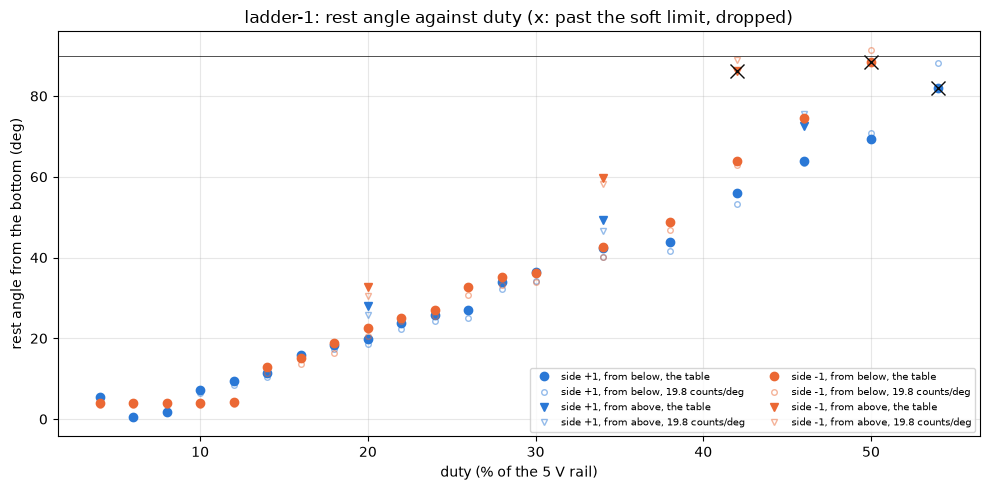

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
for side, color in ((1, BLUE), (-1, ORANGE)):
    for ap, mk in (("below", "o"), ("above", "v")):
        d = R[(R["side"] == side) & (R["approach"] == ap)]
        ax.plot(d["duty_pct"], d["theta"].abs(), mk, color=color,
                label=f"side {side:+d}, from {ap}, the table")
        ax.plot(d["duty_pct"], d["rest_deg_nominal"].abs(), mk,
                color=color, mfc="none", alpha=0.5, ms=4,
                label=f"side {side:+d}, from {ap}, 19.8 counts/deg")
    x = R[(R["side"] == side) & R["past_soft"]]
    ax.plot(x["duty_pct"], x["theta"].abs(), "x", color=INK, ms=10)
ax.axhline(90, color=INK, lw=0.5)
figures.label(ax, x="duty (% of the 5 V rail)",
              y="rest angle from the bottom (deg)",
              title="ladder-1: rest angle against duty (x: past the soft "
              "limit, dropped)")
ax.legend(fontsize=7, ncol=2)
figures.finish(fig)

What you are looking at. The rest angle against duty, filled through the table and open through the nominal 19.8 counts per degree, circles from below and triangles from above, the x marks the three rungs past the soft limits. The two scales part most near the bottom and at the ends, where the table's local scale differs most from 19.8.

From below, gravity's torque against the winding current is a line on each side. Its slope is Kt through the gears at the rising stall, and its intercept is the friction the rising arm sticks against.

In [27]:
def torque_line(d, y="tau_mn_m", x="i_w_a"):
    return results.fit_line(d[x], d[y])


FITS = {s: torque_line(BELOW[BELOW["side"] == s]) for s in (1, -1)}
FITS["pooled"] = torque_line(BELOW)
FITS_COINS = {s: torque_line(BELOW[BELOW["side"] == s], "tau_coins")
              for s in (1, -1)}
FITS_COINS["pooled"] = torque_line(BELOW, "tau_coins")
for key, f in FITS.items():
    fc = FITS_COINS[key]
    print(f"{str(key):>6s}: coins-scale {fc['intercept']:+.2f} + "
          f"{fc['slope']:.1f} i; absolute {f['intercept']:+.2f} "
          f"+/- {f['intercept_se']:.2f} + {f['slope']:.1f} +/- "
          f"{f['slope_se']:.1f} i (mN m, A); rms {f['rms']:.2f} mN m, "
          f"n {f['n']}; {f['slope'] / KT_IDEAL:.3f} of Ke x N")

     1: coins-scale -6.75 + 179.3 i; absolute -8.12 +/- 1.19 + 215.8 +/- 4.2 i (mN m, A); rms 2.03 mN m, n 17; 0.604 of Ke x N
    -1: coins-scale -7.81 + 194.7 i; absolute -9.40 +/- 1.63 + 234.3 +/- 5.6 i (mN m, A); rms 1.78 mN m, n 13; 0.656 of Ke x N
pooled: coins-scale -6.93 + 185.2 i; absolute -8.34 +/- 1.34 + 222.9 +/- 4.7 i (mN m, A); rms 2.81 mN m, n 30; 0.624 of Ke x N


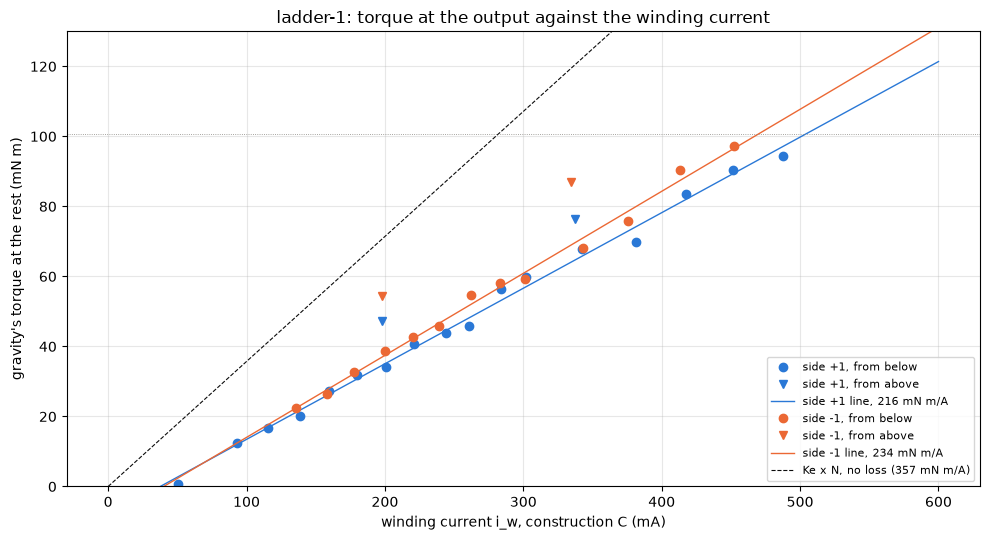

In [28]:
fig, ax = plt.subplots(figsize=(10, 5.5))
xx = np.linspace(0, 0.6, 10)
for side, color in ((1, BLUE), (-1, ORANGE)):
    for ap, mk in (("below", "o"), ("above", "v")):
        d = USE[(USE["side"] == side) & (USE["approach"] == ap)]
        ax.plot(d["i_w_a"] * 1e3, d["tau_mn_m"], mk, color=color,
                label=f"side {side:+d}, from {ap}")
    f = FITS[side]
    ax.plot(xx * 1e3, f["intercept"] + f["slope"] * xx, color=color,
            lw=1, label=f"side {side:+d} line, {f['slope']:.0f} mN m/A")
ax.plot(xx * 1e3, KT_IDEAL * xx, "--", color=INK, lw=0.8,
        label=f"Ke x N, no loss ({KT_IDEAL:.0f} mN m/A)")
ax.axhline(TAU_H, **figures.EDGE_STYLE)
ax.set_ylim(0, 130)
figures.label(ax, x="winding current i_w, construction C (mA)",
              y="gravity's torque at the rest (mN m)",
              title="ladder-1: torque at the output against the winding "
              "current")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. Gravity's torque at each rest against the winding current, the from-below lines per side, the dashed line the lossless $K_e N$ of 357.1 mN m/A and the dotted line the 100.75 mN m at horizontal. The up side reads 215.8 +/- 4.2 mN m/A and the down side 234.3 +/- 5.6, 0.604 and 0.656 of $K_e N$, with residual rms 2.03 and 1.78 mN m. Pooled, the slope is 222.9 mN m/A, 0.624 of the lossless value. The intercepts are -8.12 and -9.40 mN m, 38 and 40 mA of current before the arm takes any torque.

side +1: 6 to 50 %, largest |residual| 4.27 mN m, trend on duty -0.002 +/- 0.042 mN m per %
side -1: 14 to 46 %, largest |residual| 3.15 mN m, trend on duty +0.001 +/- 0.055 mN m per %


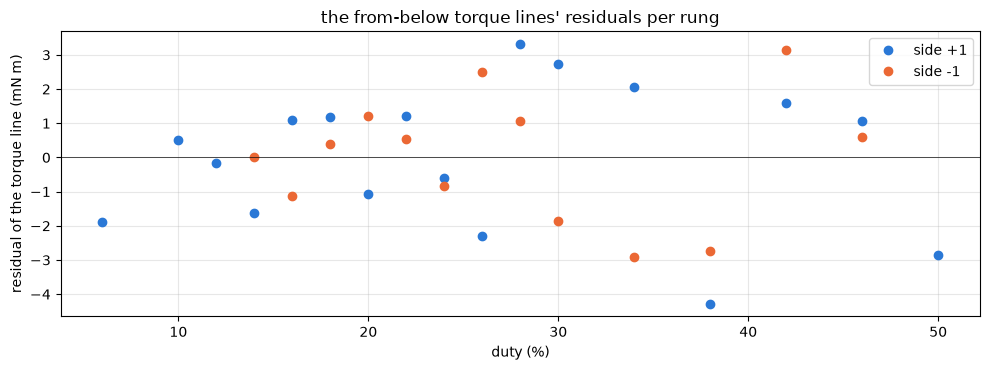

In [29]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for side, color in ((1, BLUE), (-1, ORANGE)):
    d = BELOW[BELOW["side"] == side]
    res = FITS[side]["resid"]
    ax.plot(d["duty_pct"], res, "o", color=color, label=f"side {side:+d}")
    tr = results.fit_line(d["duty_pct"], res)
    print(f"side {side:+d}: {d['duty_pct'].min()} to "
          f"{d['duty_pct'].max()} %, largest |residual| "
          f"{np.abs(res).max():.2f} mN m, trend on duty "
          f"{tr['slope']:+.3f} +/- {tr['slope_se']:.3f} mN m per %")
ax.axhline(0, color=INK, lw=0.5)
figures.label(ax, x="duty (%)", y="residual of the torque line (mN m)",
              title="the from-below torque lines' residuals per rung")
ax.legend()
figures.finish(fig)

What you are looking at. Each from-below rung's residual about its side's line. They scatter with no trend in duty, -0.002 +/- 0.042 mN m per % on the up side over 6 to 50 % and +0.001 +/- 0.055 on the down side over 14 to 46 %, the largest 4.27 and 3.15 mN m. The line holds over the whole range each side was read.

In [30]:
for side in (1, -1):
    d = BELOW[BELOW["side"] == side]
    inside = torque_line(d[~d["outside_table"]])
    crest = torque_line(d, x="i_crest_a")
    nominal = results.fit_line(
        d["i_w_a"], gravity_coins(d["rest_deg_nominal"]) * SCALE)
    print(f"side {side:+d}: table-only {inside['slope']:.1f} +/- "
          f"{inside['slope_se']:.1f}, {inside['intercept']:+.2f} (n "
          f"{inside['n']}); crest current {crest['slope']:.1f}, "
          f"{crest['intercept']:+.2f}; nominal 19.8 counts/deg "
          f"{nominal['slope']:.1f}, {nominal['intercept']:+.2f}")
TABLE_ONLY = {s: torque_line(BELOW[(BELOW["side"] == s)
                                   & ~BELOW["outside_table"]])
              for s in (1, -1)}

side +1: table-only 219.0 +/- 5.3, -8.71 (n 15); crest current 221.3, -13.27; nominal 19.8 counts/deg 216.2, -10.21
side -1: table-only 232.9 +/- 6.9, -9.10 (n 12); crest current 240.3, -15.02; nominal 19.8 counts/deg 240.5, -13.55


Three variants of the same lines. Without the rungs the table had to extrapolate past its ends the slopes read 219.0 +/- 5.3 and 232.9 +/- 6.9 mN m/A. With the as-read crest current in place of $i_w$ they read 221.3 and 240.3, the intercepts -13.27 and -15.02. Through the nominal 19.8 counts per degree they read 216.2 and 240.5.

In [31]:
sens = []
for b in (BOTTOM_LO, BOTTOM, BOTTOM_HI):
    tau = gravity_coins(theta_deg(BELOW["rest_pos"], b)) * SCALE
    d = BELOW.assign(tau_b=tau)
    for key, part in ((1, d[d["side"] == 1]), (-1, d[d["side"] == -1]),
                      ("pooled", d)):
        f = torque_line(part, "tau_b")
        sens.append({"bottom": b, "line": str(key), "slope": f["slope"],
                     "slope_se": f["slope_se"], "intercept": f["intercept"],
                     "intercept_se": f["intercept_se"], "rms": f["rms"]})
SENS = pd.DataFrame(sens)
show(SENS, n=None)
for line, g in SENS.groupby("line", sort=False):
    s = g.set_index("bottom")
    i_pct = np.ptp(s["intercept"]) / abs(s.loc[BOTTOM, "intercept"]) * 100
    print(f"{line:>6s}: slope spread {np.ptp(s['slope']) / s.loc[BOTTOM,
          'slope'] * 100:.1f} % over the three, {BOTTOM} against "
          f"{BOTTOM_HI} {abs(s.loc[BOTTOM, 'slope'] - s.loc[BOTTOM_HI,
          'slope']) / s.loc[BOTTOM, 'slope'] * 100:.2f} %; intercept "
          f"spread {np.ptp(s['intercept']):.2f} mN m, {i_pct:.0f} % of "
          f"its value")

,bottom,line,slope,slope_se,intercept,intercept_se,rms
0,2007,1,215.189,4.485,-6.979,1.273,2.173
1,2007,-1,236.927,5.750,-11.173,1.669,1.823
2,2007,pooled,222.496,4.093,-8.138,1.173,2.461
3,2021,1,215.821,4.192,-8.124,1.190,2.031
4,2021,-1,234.271,5.603,-9.404,1.626,1.776
5,2021,pooled,222.857,4.677,-8.339,1.341,2.813
6,2024,1,215.793,4.127,-8.335,1.171,1.999
7,2024,-1,233.646,5.570,-8.991,1.616,1.766
8,2024,pooled,222.814,4.889,-8.347,1.401,2.940


     1: slope spread 0.3 % over the three, 2021 against 2024 0.01 %; intercept spread 1.36 mN m, 17 % of its value
    -1: slope spread 1.4 % over the three, 2021 against 2024 0.27 %; intercept spread 2.18 mN m, 23 % of its value
pooled: slope spread 0.2 % over the three, 2021 against 2024 0.02 %; intercept spread 0.21 mN m, 3 % of its value


### The bottom's effect

The same lines with the bottom at each of the three candidates. The pooled slope moves 0.2 % across them and each side's slope up to 1.4 %, the down side the most. 2021 against 2024 moves every slope under 0.3 %. The intercepts move 1.36 and 2.18 mN m, 17 and 23 % of their small values, since they sit near zero. The bottom's effect is folded into the brackets below, each spanning the three bottoms as well as the fit's standard error about each.

In [32]:
def bracket(line, col):
    """(value at the bottom of record, lo, hi): lo and hi span the three
    bottoms and the fit's se about each."""
    g = SENS[SENS["line"] == line].set_index("bottom")
    v = g.loc[BOTTOM, col]
    return (v, (g[col] - g[col + "_se"]).min(),
            (g[col] + g[col + "_se"]).max())


KT_GEAR = {s: bracket(str(s), "slope") for s in (1, -1)}
KT_GEAR["pooled"] = bracket("pooled", "slope")
INTERCEPT = {s: bracket(str(s), "intercept") for s in (1, -1)}
for s in (1, -1, "pooled"):
    v, lo, hi = KT_GEAR[s]
    print(f"{str(s):>6s}: Kt through the gears {v:.1f} ({lo:.1f} to "
          f"{hi:.1f}) mN m/A, {v / KT_IDEAL:.3f} ({lo / KT_IDEAL:.3f} to "
          f"{hi / KT_IDEAL:.3f}) of Ke x N")
for s in (1, -1):
    v, lo, hi = INTERCEPT[s]
    print(f"side {s:+d}: intercept {v:+.2f} ({lo:+.2f} to {hi:+.2f}) mN m"
          f", {-v / FITS[s]['slope'] * 1e3:.0f} mA at zero torque")

     1: Kt through the gears 215.8 (210.7 to 220.0) mN m/A, 0.604 (0.590 to 0.616) of Ke x N
    -1: Kt through the gears 234.3 (228.1 to 242.7) mN m/A, 0.656 (0.639 to 0.680) of Ke x N
pooled: Kt through the gears 222.9 (217.9 to 227.7) mN m/A, 0.624 (0.610 to 0.638) of Ke x N
side +1: intercept -8.12 (-9.51 to -5.71) mN m, 38 mA at zero torque
side -1: intercept -9.40 (-12.84 to -7.37) mN m, 40 mA at zero torque


Kt through the gears at the rising stall is 215.8 (210.7 to 220.0) mN m/A on the up side and 234.3 (228.1 to 242.7) on the down side, 222.9 (217.9 to 227.7) pooled. That is 0.604, 0.656 and 0.624 of $K_e N$, likely the train's efficiency at a rising stall, taken with this servo's own Ke of 1.1591 mV s/rad. The type's Ke, 1.1684, is slightly higher. The intercepts are -8.12 (-9.51 to -5.71) and -9.40 (-12.84 to -7.37) mN m.

The resistance result's as-read line predicts more current at a given duty than these 3 s holds drew. Section 8 takes that up.

## 5. The deadband

The plan meant the from-above rungs and the steps to measure the friction band under load. Both turned out to sit inside it.

In [33]:
above = []
for _, a in R[R["approach"] == "above"].iterrows():
    df, _ = load_sweep(DATA / "ladder-1" / f"ladder/{int(a['k'])}")
    seg = {s: g for s, g in df.groupby("seg")}
    same = R[(R["approach"] == "below") & (R["side"] == a["side"])]
    b = same[same["duty_pct"] == a["duty_pct"]].iloc[0]
    d6 = same[same["duty_pct"] == a["duty_pct"] + 6]
    above.append({
        "k": a["k"], "side": a["side"], "duty_pct": a["duty_pct"],
        "step_first": seg[3]["pos"].iloc[:200].median(),   # first 10 ms
        "step_last": seg[3]["pos"].iloc[-200:].median(),   # last 10 ms
        "hold_end": seg[5]["pos"].iloc[-200:].median(),    # the d hold
        "theta_above": a["theta"], "theta_below": b["theta"],
        "theta_d6_below": d6["theta"].iloc[0] if len(d6) else np.nan,
        "i_w_a": b["i_w_a"], "v_on_v": b["v_on_v"], "v_c_v": b["v_c_v"]})
ABOVE = pd.DataFrame(above)
ABOVE["moved"] = (ABOVE[["step_first", "step_last", "hold_end"]]
                  .nunique(axis=1) > 1)
show(ABOVE.drop(columns=["i_w_a", "v_on_v", "v_c_v"]), n=None)
print(f"from-above rungs whose pos changed after the step down: "
      f"{int(ABOVE['moved'].sum())} of {len(ABOVE)}")

,k,side,duty_pct,step_first,step_last,hold_end,theta_above,theta_below,theta_d6_below,moved
0,20,1,20,2515.000,2515.000,2515.000,27.898,19.798,27.112,False
1,21,1,34,2927.000,2927.000,2927.000,49.269,42.363,NaN,False
2,22,1,46,3501.000,3501.000,3501.000,72.696,63.832,NaN,False
3,42,-1,20,1402.000,1402.000,1402.000,-32.769,-22.541,-32.819,False
4,43,-1,34,855.000,855.000,855.000,-59.746,-42.506,NaN,False
5,44,-1,42,247.000,247.000,247.000,-86.290,-63.982,NaN,False


from-above rungs whose pos changed after the step down: 0 of 6


In [34]:
ABOVE_OVER = 6          # % of duty, the plan's step down to the duty
# 6 % at the rung's own volts per amp, through that side's torque line
r_app = ABOVE["v_c_v"] / ABOVE["i_w_a"]
di_a = ABOVE_OVER / 100 * ABOVE["v_on_v"] / r_app
slope = ABOVE["side"].map({1: FITS[1]["slope"], -1: FITS[-1]["slope"]})
ABOVE["step_mn_m"] = slope * di_a
ABOVE["step_ma"] = di_a * 1e3
show(ABOVE[["k", "side", "duty_pct", "step_ma", "step_mn_m"]], n=None)
BAND_LO = (ABOVE["step_mn_m"].min(), ABOVE["step_mn_m"].max())
print(f"the step down took {ABOVE['step_ma'].min():.0f} to "
      f"{ABOVE['step_ma'].max():.0f} mA off, {BAND_LO[0]:.1f} to "
      f"{BAND_LO[1]:.1f} mN m absolute (coins-scale "
      f"{BAND_LO[0] / SCALE:.1f} to {BAND_LO[1] / SCALE:.1f})")

,k,side,duty_pct,step_ma,step_mn_m
0,20,1,20,71.333,15.395
1,21,1,34,67.565,14.582
2,22,1,46,64.087,13.831
3,42,-1,20,70.984,16.630
4,43,-1,34,67.655,15.850
5,44,-1,42,64.683,15.153


the step down took 64 to 71 mA off, 13.8 to 16.6 mN m absolute (coins-scale 11.5 to 13.8)


The from-above rungs held a duty 6 % higher, then stepped to the duty. The pot read the same count in the step's first and last 10 ms and at the end of the hold, so 0 of 6 moved. Each from-above rest is simply the rest at the duty 6 % higher, k20's 27.90 degrees against the 26 % rung's 27.11 from below and k42's -32.77 against -32.82. The half difference of the from-above and from-below rests is the ladder's rung spacing, not the friction.

What the data give is a bound. The step took 64 to 71 mA off, 13.8 to 16.6 mN m of motor torque through each side's line, and the arm did not fall, at 20, 34 and 46 % on the up side and at 20, 34 and 42 % on the down side. So the friction band, the rise's friction plus the fall's, is at least 13.8 to 16.6 mN m at each of those rests. Whether the band grows with load, bounds alone do not show.

In [35]:
def step_row(r, edge, before, after, held, i, a, w):
    """The current's jump and settled change and the angle's change of
    one edge, per % of duty."""
    n = len(before)
    d_duty = ((held - np.median(before["duty_counts"].abs())) / ARR * 100
              if n else np.nan)
    i_before = before["i_a"].mean() if n else np.nan
    th_before = theta_deg(before["pos"].median(), BOTTOM) if n else np.nan
    th_after = theta_deg(after["pos"].iloc[-END_ROWS:].median(), BOTTOM)
    peak = np.nanargmax(np.abs(w))
    return {"k": r["k"], "side": r["side"], "base_pct": r["duty_pct"],
            "step_pct": r["step_pct"], "edge": edge, "d_duty": d_duty,
            "i_before_ma": i_before * 1e3,
            "di_jump_ma": (i[JUMP].mean() - i_before) * 1e3,
            "di_end_ma": (i[-END_ROWS:].mean() - i_before) * 1e3,
            "i_drift_ma": (i[-END_ROWS:].mean() - i[JUMP].mean()) * 1e3,
            "theta_before": th_before, "d_theta": th_after - th_before,
            "w_peak_rev_s": w[peak] / 360 * GEAR,
            "v_on_v": abs(after["vdiff_v"].iloc[40:].mean())}

In [36]:
CHAINS = pd.read_csv(DATA / "steps-1/chains.csv")
STEP_PCT = 5            # % of duty, the plan's step
JUMP = slice(20, 60)    # rows, 1 to 3 ms after the duty register flips
END_ROWS = 1000         # rows, the window's last 50 ms
step_rows, STEP_TRACES = [], {}
for _, r in CHAINS.iterrows():
    df, _ = load_sweep(DATA / "steps-1" / r["folder"], BOTTOM)
    for seg, edge in ((3, "step"), (4, "back")):
        s = df[df["seg"] == seg].reset_index(drop=True)
        e, held = tel.flip_row(s)   # the first row at the new duty
        if e >= 100:                # the 20 ms before the flip
            before = s.iloc[max(0, e - 400):e]
        elif seg == 4:              # the step's last 50 ms instead
            before = df[df["seg"] == 3].iloc[-END_ROWS:]
        else:                       # the hold was not streamed
            before = s.iloc[:e]
        after = s.iloc[e:]
        i = after["i_a"].to_numpy()
        a = angle_of(after["pos"].to_numpy())
        w = pot_speed(after["pos"].to_numpy(), 100)   # deg/s, 5 ms half
        step_rows.append(step_row(r, edge, before, after, held, i, a, w))
        STEP_TRACES[(r["k"], edge)] = (np.arange(len(after)) / FS, i,
                                       a - angle_of(before["pos"].median())
                                       if len(before) else a * np.nan)
STEPS = pd.DataFrame(step_rows)
print(f"{len(CHAINS)} chains, {len(STEPS)} edges; the jump "
      f"{JUMP.start / FS * 1e3:.0f} to {JUMP.stop / FS * 1e3:.0f} ms after "
      f"the flip, the end the last {END_ROWS / FS * 1e3:.0f} ms")

12 chains, 24 edges; the jump 1 to 3 ms after the flip, the end the last 50 ms


In [37]:
STEPS["k_jump"] = STEPS["di_jump_ma"] / STEPS["d_duty"]   # mA per %
STEPS["k_end"] = STEPS["di_end_ma"] / STEPS["d_duty"]     # mA per %
STEPS["k_theta"] = STEPS["d_theta"] / STEPS["d_duty"]     # deg per %
show(STEPS[["k", "side", "base_pct", "step_pct", "edge", "d_duty",
            "theta_before", "d_theta", "i_before_ma", "di_jump_ma",
            "di_end_ma", "k_jump", "k_end", "w_peak_rev_s"]], n=None)
UP = STEPS[STEPS["edge"] == "step"].dropna(subset=["d_duty"])
print(f"current per % at the edge {UP['k_jump'].mean():.2f} +/- "
      f"{UP['k_jump'].std(ddof=1):.2f} mA/%, 300 ms later "
      f"{UP['k_end'].mean():.2f} +/- {UP['k_end'].std(ddof=1):.2f} "
      f"(n {len(UP)}); free steps {K_I_FREE:.2f} mA/%")
print(f"V_on / 100 / R: {UP['v_on_v'].mean() / R_LOCKED * 10:.2f} mA/% "
      f"locked R, {UP['v_on_v'].mean() / 100 / (UP['k_jump'].mean() / 1e3):.2f}"
      f" ohm for the measured jump")
print(f"angle per % {UP['k_theta'].mean():+.3f} +/- "
      f"{UP['k_theta'].std(ddof=1):.3f} deg/%, largest |change| "
      f"{UP['d_theta'].abs().max():.2f} deg; peak pot speed "
      f"{STEPS['w_peak_rev_s'].abs().max():.1f} rev/s at the motor, mean "
      f"{STEPS['w_peak_rev_s'].abs().mean():.1f} "
      f"(free k_w x 5 % = {K_W_FREE * STEP_PCT:.1f})")

,k,side,base_pct,step_pct,edge,d_duty,theta_before,d_theta,i_before_ma,di_jump_ma,di_end_ma,k_jump,k_end,w_peak_rev_s
0,0,1,20,5,step,5.000,21.384,0.061,220.787,49.993,49.727,9.999,9.945,-2.568
1,0,1,20,5,back,-5.000,21.445,0.000,270.514,-51.760,-51.218,10.352,10.244,-2.826
2,1,1,20,-5,step,-5.000,20.402,-0.126,220.913,-53.105,-53.066,10.621,10.613,-2.537
3,1,1,20,-5,back,5.000,20.277,0.000,167.847,51.789,51.317,10.358,10.263,-2.444
4,2,1,34,5,step,5.000,42.724,-0.155,361.881,48.568,46.384,9.714,9.277,-2.573
5,2,1,34,5,back,-5.000,42.570,0.000,408.264,-49.049,-49.899,9.810,9.980,-2.217
6,3,1,34,-5,step,-5.000,42.415,0.052,359.867,-51.003,-51.350,10.201,10.270,-2.380
7,3,1,34,-5,back,5.000,42.467,0.000,308.517,50.523,49.644,10.105,9.929,-2.322
8,4,1,46,5,step,5.000,63.981,-0.334,472.893,47.356,44.420,9.471,8.884,-1.770
9,4,1,46,5,back,-5.000,63.647,0.000,517.312,-50.169,-50.413,10.034,10.083,1.806


current per % at the edge 9.93 +/- 0.38 mA/%, 300 ms later 9.81 +/- 0.58 (n 10); free steps 1.08 mA/%
V_on / 100 / R: 11.22 mA/% locked R, 4.77 ohm for the measured jump
angle per % -0.011 +/- 0.026 deg/%, largest |change| 0.33 deg; peak pot speed 2.8 rev/s at the motor, mean 2.1 (free k_w x 5 % = 28.2)


In [38]:
UP["drift_pct"] = UP["i_drift_ma"] / (UP["i_before_ma"]
                                     + UP["di_jump_ma"]) * 100
print(f"current drift over the 300 ms after the jump "
      f"{UP['i_drift_ma'].min():+.1f} to {UP['i_drift_ma'].max():+.1f} mA")
print("mean drift by base duty, %: " + ", ".join(
    f"{b} % {x:+.2f}" for b, x in UP.groupby("base_pct")["drift_pct"]
    .mean().items()))
back = STEPS[STEPS["edge"] == "back"].set_index("k")
end_back = back["i_before_ma"] + back["di_end_ma"]
start = UP.set_index("k")["i_before_ma"]
BACK_DIFF = (end_back - start).dropna()
print(f"the step back ends {BACK_DIFF.min():+.1f} to {BACK_DIFF.max():+.1f}"
      f" mA from the current before the step, at most "
      f"{(BACK_DIFF / start).abs().max() * 100:.1f} % (largest drift over "
      f"one window {UP['drift_pct'].abs().max():.2f} %); the angle back "
      f"{back['d_theta'].abs().max():.2f} deg at most")
NO_BEFORE = STEPS[(STEPS["edge"] == "step") & STEPS["d_duty"].isna()]
print(f"step edges with no rows before the flip: k "
      f"{NO_BEFORE['k'].tolist()}")
print(f"|di| per 5 % step: {UP['di_jump_ma'].abs().min():.0f} to "
      f"{UP['di_jump_ma'].abs().max():.0f} mA")

current drift over the 300 ms after the jump -2.9 to +0.0 mA
mean drift by base duty, %: 20 % -0.04, 34 % -0.16, 42 % -0.34, 46 % -0.39
the step back ends -6.0 to +1.0 mA from the current before the step, at most 1.3 % (largest drift over one window 0.56 %); the angle back 0.04 deg at most
step edges with no rows before the flip: k [6, 7]
|di| per 5 % step: 47 to 53 mA


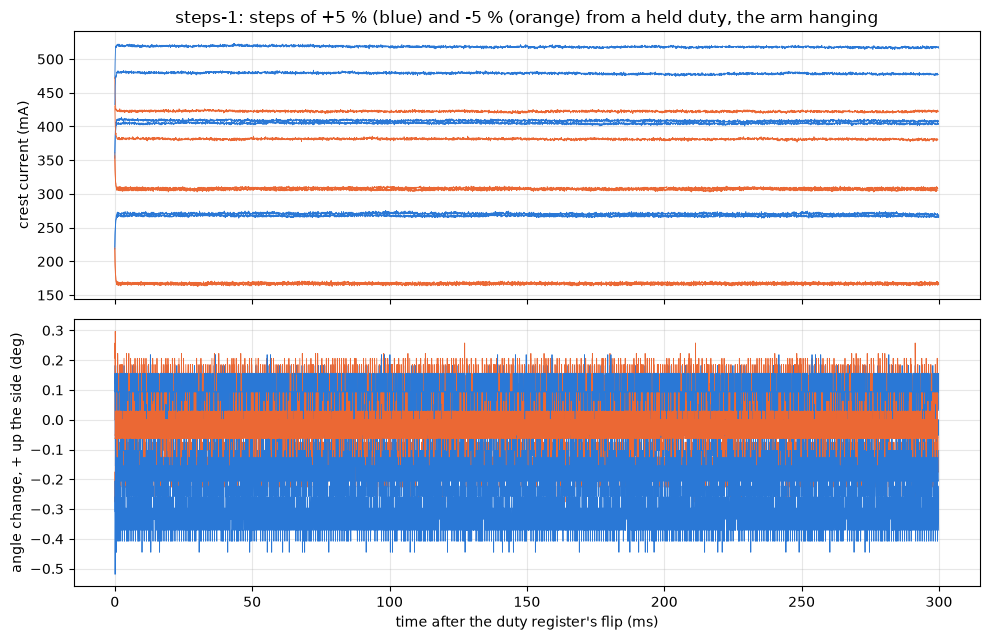

In [39]:
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
for (k, edge), (t, i, a) in STEP_TRACES.items():
    if edge != "step":
        continue
    r = CHAINS.set_index("k").loc[k]
    m = t < 0.3
    color = BLUE if r["step_pct"] > 0 else ORANGE
    axs[0].plot(t[m] * 1e3, i[m] * 1e3, lw=0.6, color=color)
    axs[1].plot(t[m] * 1e3, a[m] * np.sign(r["side"]), lw=0.6, color=color)
figures.label(axs[0], y="crest current (mA)",
              title="steps-1: steps of +5 % (blue) and -5 % (orange) from "
              "a held duty, the arm hanging")
figures.label(axs[1], x="time after the duty register's flip (ms)",
              y="angle change, + up the side (deg)")
figures.finish(fig)

What you are looking at. The crest current (top) and the angle change (bottom) after each step edge, the +5 % steps in blue and the -5 % in orange. The current steps and stays. The angle does not move.

A step of 5 % changes the current by 9.93 +/- 0.38 mA per % 1 to 3 ms after the edge and 9.81 +/- 0.58 mA per % over the window's last 50 ms, n 10, 47 to 53 mA a step. Two of the twelve step edges, k6 and k7, have no rows before them, since the duty flips on row 0 of the streamed segment, so they are left out. Their back edges are measured and still. The measured jump is a stalled winding at 4.77 ohm. The free steps give 1.08 mA per %, since a free rotor turns the volts into speed and the held arm turns them all into current.

The angle changes -0.011 +/- 0.026 degrees per %, the largest change 0.33 degrees, and the pot's peak slope reads 2.1 rev/s at the motor on average, its noise. No delay and no time constant exist to report. Inside +/- 5 % of duty the load's step response is a pure current step and a still output. The current drifts down by up to 2.9 mA over the 300 ms after the jump, at most 0.56 % in one window, at the top duties. The step back leaves the current -6.0 to +1.0 mA from where it was before the step, at most 1.3 % over the two windows, consistent with that drift. The angle comes back to within 0.04 degrees.

So a constant-duty hold has a deadband of at least +/- 5 % of duty, 47 to 53 mA at the motor, at every angle tried. For stage 5 this is the floor a position loop has to push through before the output answers. It is a lower bound, and its size needs larger steps (section 10).

## 6. The two sides

The two sides' lines differ in slope. What the data say about whether the train itself is asymmetric.

In [40]:
matched = R[(R["approach"] == "below") & R["moved"] & ~R["past_soft"]]
m = matched.pivot_table(index="duty_pct", columns="side",
                        values=["i_w_a", "rest_deg_nominal", "theta",
                                "tau_mn_m"]).dropna()
SIDES = pd.DataFrame({
    "i_dn_over_up": m[("i_w_a", -1)] / m[("i_w_a", 1)],
    "theta_nominal": m[("rest_deg_nominal", -1)].abs()
    / m[("rest_deg_nominal", 1)],
    "theta_table": m[("theta", -1)].abs() / m[("theta", 1)],
    "tau_per_a": (m[("tau_mn_m", -1)] / m[("i_w_a", -1)])
    / (m[("tau_mn_m", 1)] / m[("i_w_a", 1)])})
show(SIDES.reset_index(), n=None)
for col in SIDES:
    x = SIDES[col]
    print(f"{col:14s} down over up {x.mean():.4f} sd {x.std(ddof=1):.4f}"
          f" se {x.std(ddof=1) / np.sqrt(len(x)):.4f} (n {len(x)})")
at46 = SIDES.loc[46]
print(f"at 46 %: nominal {at46['theta_nominal']:.2f}, table "
      f"{at46['theta_table']:.2f}, torque per amp {at46['tau_per_a']:.2f}")

,duty_pct,i_dn_over_up,theta_nominal,theta_table,tau_per_a
0,14,0.978,1.113,1.111,1.134
1,16,0.991,0.919,0.966,0.976
2,18,0.987,0.945,1.023,1.035
3,20,0.996,1.118,1.139,1.137
4,22,0.998,1.086,1.052,1.051
5,24,0.979,1.057,1.044,1.063
6,26,1.006,1.222,1.210,1.182
7,28,0.999,1.033,1.034,1.030
8,30,0.998,0.994,0.992,0.995
9,34,1.001,1.000,1.003,1.001


i_dn_over_up   down over up 0.9929 sd 0.0088 se 0.0024 (n 13)
theta_nominal  down over up 1.0738 sd 0.0926 se 0.0257 (n 13)
theta_table    down over up 1.0765 sd 0.0752 se 0.0209 (n 13)
tau_per_a      down over up 1.0673 sd 0.0613 se 0.0170 (n 13)
at 46 %: nominal 1.17, table 1.17, torque per amp 1.07


In [41]:
def split_sigma(fits):
    """The down side's slope less the up side's, in their joint se."""
    d = fits[-1]["slope"] - fits[1]["slope"]
    return d / np.hypot(fits[-1]["slope_se"], fits[1]["slope_se"])


SPLIT_ALL = split_sigma(FITS)
SPLIT_TABLE = split_sigma(TABLE_ONLY)
for name, f, sig in (("all rungs", FITS, SPLIT_ALL),
                     ("table-only", TABLE_ONLY, SPLIT_TABLE)):
    print(f"{name:10s}: up {f[1]['slope']:.1f} +/- {f[1]['slope_se']:.1f}"
          f", down {f[-1]['slope']:.1f} +/- {f[-1]['slope_se']:.1f} "
          f"mN m/A, {sig:.1f} sigma")
SIDE_TPA = {}
for b in (BOTTOM_LO, BOTTOM, BOTTOM_HI):
    th = np.abs(theta_deg(matched["rest_pos"], b))
    t = matched.assign(tpa=gravity_coins(th) / matched["i_w_a"])
    p = t.pivot_table(index="duty_pct", columns="side",
                      values="tpa").dropna()
    x = p[-1] / p[1]
    SIDE_TPA[b] = x.mean()
    print(f"bottom {b}: torque per amp down over up {x.mean():.3f} sd "
          f"{x.std(ddof=1):.3f} se {x.std(ddof=1) / np.sqrt(len(x)):.3f}")
edges = R[R["approach"] == "below"].sort_values("duty_pct")
for side in (1, -1):
    e = edges[edges["side"] == side]
    first = e[e["moved"]]["duty_pct"].min()
    still = e[~e["moved"] & (e["duty_pct"] < first)]
    print(f"side {side:+d}: first rung that moved {first} %; before it "
          f"{len(still)} rungs held, starting from "
          f"{sorted(still['first_pos'].unique().tolist())} counts")

all rungs : up 215.8 +/- 4.2, down 234.3 +/- 5.6 mN m/A, 2.6 sigma
table-only: up 219.0 +/- 5.3, down 232.9 +/- 6.9 mN m/A, 1.6 sigma
bottom 2007: torque per amp down over up 1.014 sd 0.065 se 0.018
bottom 2021: torque per amp down over up 1.067 sd 0.061 se 0.017
bottom 2024: torque per amp down over up 1.080 sd 0.063 se 0.018
side +1: first rung that moved 6 %; before it 1 rungs held, starting from [2106.0] counts
side -1: first rung that moved 14 %; before it 5 rungs held, starting from [1934.0, 1938.0] counts


At matched duty the winding current is the same both ways, down over up 0.9929 sd 0.0088 over 13 duties, so nothing electrical separates the sides. The angle ratio down over up is 1.074 through the nominal scale and 1.077 through the table, 1.17 for both at 46 %. The torque per amp reads 1.067 down over up at the bottom of record, se 0.017, and it moves with the bottom, 1.014 at 2007 and 1.080 at 2024. The slopes differ by 2.6 sigma with every rung and by 1.6 sigma once the rungs the table had to extrapolate are left out.

So the side split rests on two things this sitting leaves open, where the bottom is and the table's ends. A direction asymmetry of the train is not established. The candidates the data do not yet separate are a real asymmetry of the train, the table's extrapolation past its ends, the commutation angle each rest happens to sit at, and a radial-load term on the pot. Warming does not move torque per amp, and the down side's currents are 0.9929 of the up side's in any case. The inner-cup sitting, with the sides alternated at each duty and its own bottom, is the test of the split.

The breakaway differs too. The up side moved at 6 %, from a rest at 1848 counts on the far side of the bottom, with gravity helping. The down side held through five rungs, 4 to 12 %, all from rests at 1934 and 1938 counts, one rotor angle five times, and first moved at 14 %. That is one sample a side.

## 7. The lift and the fall

The free ladder's rungs at 5 V give the free speed at 30 and 40 % each way and at -20 %. The +20 % has no rung and is read off the free steps' speed line, 86.3 rev/s.

In [42]:
FREE = {}               # (duty %, direction): (rev/s, crest mA) on 5 V
for key, v in LADDER["rungs"].items():
    rail, _, pct, _, d = key.split()
    if rail == "5":
        FREE[(int(pct), int(d))] = (v["speed_rev_s"]["value"],
                                    v["i_crest_ma"]["value"])
LINE_A, LINE_B = (FREE_STEPS["speed_duty_line_slope_rev_s_per_pct"]["value"],
                  FREE_STEPS["speed_duty_line_intercept_rev_s"]["value"])
print({k: round(v[0], 1) for k, v in FREE.items()})
print(f"the free steps' speed line at 20 %: {LINE_A * 20 + LINE_B:.1f} "
      f"rev/s")

{(20, -1): 82.1, (30, -1): 140.1, (30, 1): 136.3, (40, -1): 198.2, (40, 1): 192.7, (60, -1): 311.8, (60, 1): 299.9}
the free steps' speed line at 20 %: 86.3 rev/s


In [43]:
WIN_DEG = 2.0           # deg, half the angle window a speed is read over
TAKE_UP_S = 0.03        # s, the lash and the first spin left out
SPEED_HALF = 250        # rows, the pot slope's half window, 12.5 ms


def lift_row(r):
    d = DRIVE_ROWS[r["k"]]
    t = np.arange(len(d)) / FS
    th = np.abs(theta_deg(d["pos"], BOTTOM))
    w_motor = pot_speed(d["pos"].to_numpy(), SPEED_HALF) / 360 * GEAR
    v_on = np.abs(d["vdiff_v"].to_numpy())
    _, i_w = construction_c(d["D"].to_numpy(), v_on, d["i_a"].to_numpy())
    out = {"k": r["k"], "side": r["side"], "duty_pct": r["duty_pct"],
           "repeat": r["repeat"], "theta_start": th[0],
           "theta_top": th[-400:].mean(),
           "moving_at_cut": abs(np.nanmean(w_motor[-600:-250])) * 360
           / GEAR > 5}
    for a0 in (10, 20, 30, 40):
        m = ((th > a0 - WIN_DEG) & (th < a0 + WIN_DEG)
             & np.isfinite(w_motor) & (t > TAKE_UP_S))
        ok = m.sum() > 50
        out[f"w_{a0}"] = abs(np.nanmean(w_motor[m])) if ok else np.nan
        out[f"i_{a0}"] = np.nanmean(i_w[m]) if ok else np.nan
    free = FREE.get((r["duty_pct"], r["side"]), (np.nan, np.nan))
    out["w_free"], out["i_free"] = free[0], free[1] / 1e3
    LIFT_TRACES[r["k"]] = (th, np.abs(w_motor))
    return out


LIFT_TRACES = {}
print(f"speed over +/- {SPEED_HALF / FS * 1e3:.1f} ms, windows of +/- "
      f"{WIN_DEG:.0f} deg, from {TAKE_UP_S * 1e3:.0f} ms in")
LIFT = pd.DataFrame([lift_row(r) for _, r in CYCLES.iterrows()])
show(LIFT, n=None)

speed over +/- 12.5 ms, windows of +/- 2 deg, from 30 ms in


,k,side,duty_pct,repeat,theta_start,theta_top,moving_at_cut,w_10,i_10,w_20,i_20,w_30,i_30,w_40,i_40,w_free,i_free
0,0,1,20,0,0.054,20.902,False,51.946,0.105,3.840,0.194,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,20,1,10.346,20.676,False,53.780,0.101,4.019,0.193,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1,30,0,9.947,36.443,False,96.841,0.136,82.792,0.169,42.366,0.235,NaN,NaN,136.324,0.105
3,3,1,30,1,0.000,36.866,False,101.803,0.133,80.199,0.171,44.191,0.232,NaN,NaN,136.324,0.105
4,4,1,40,0,0.431,48.722,True,142.310,0.171,136.873,0.180,110.620,0.225,75.710,0.291,192.665,0.117
5,5,1,40,1,1.200,49.107,True,136.395,0.175,137.211,0.179,111.562,0.224,77.439,0.289,192.665,0.117
6,6,-1,20,0,1.478,21.006,False,64.560,0.104,4.079,0.196,NaN,NaN,NaN,NaN,82.098,0.091
7,7,-1,20,1,9.719,22.832,False,61.312,0.098,22.525,0.169,NaN,NaN,NaN,NaN,82.098,0.091
8,8,-1,30,0,2.708,38.745,False,122.414,0.122,102.862,0.161,62.539,0.222,5.336,0.300,140.136,0.101
9,9,-1,30,1,2.641,38.893,False,124.630,0.123,102.486,0.162,63.773,0.222,5.661,0.298,140.136,0.101


The pot's slope carries a ripple of a couple of degrees, so each lift's speed is the mean over a window of +/- 2 degrees at 10, 20, 30 and 40 degrees, from 30 ms in, past where the motor spins through the lash.

At 10 degrees the motor turns at 52 to 54 rev/s at +20 %, 97 to 102 at +30 %, 136 to 142 at +40 %, 61 to 65 at -20 %, 122 to 125 at -30 % and 170 at -40 %. The -40 % repeat that started 7.1 degrees out read 106. The free speeds are 86 (the line), 136, 193, 82, 140 and 198.

In [44]:
FREE_DIR = PAIR_DIR / "ladder" / "capture-1"   # the free ladder
WINDOW_MS, WINDOW_MIN_MS = 100, 20      # ms, the ladder's spin window
free_rows = []
fcyc = pd.read_csv(FREE_DIR / "cycles.csv")
for _, r in fcyc[(fcyc["volts_set"] == 5.0)
                 & fcyc["duty_pct"].isin((20, 30, 40))].iterrows():
    df, _ = load_sweep(FREE_DIR / r["folder"])
    for seg, g in df[df["cmd_duty_q15"] != 0].groupby("seg"):
        ticks = g["duty_counts"].abs()
        held = g[ticks == ticks.iloc[len(g) // 2:].median()]
        n = int(min(WINDOW_MS * FS / 1e3, len(held) // 2))
        n = min(max(n, int(WINDOW_MIN_MS * FS / 1e3)), len(held))
        win = held.iloc[-n:]            # the held duty's last window
        v_on = abs(win["vdiff_v"].mean())
        D = win["D"].median()
        _, i_c = construction_c(D, v_on, win["i_a"].mean())
        free_rows.append({"duty_pct": r["duty_pct"],
                          "side": int(np.sign(g["duty_counts"].iloc[-1])),
                          "i_crest_a": win["i_a"].mean(), "i_c_a": i_c})
FREE_C = pd.DataFrame(free_rows).groupby(["duty_pct", "side"]).mean()
show(FREE_C.reset_index(), n=None)
print("ladder result's crest, mA: " + ", ".join(
    f"{p} % {d:+d} {v[1]:.1f}" for (p, d), v in FREE.items()
    if p in (20, 30, 40)))

,duty_pct,side,i_crest_a,i_c_a
0,20,-1,0.088,0.070
1,20,1,0.091,0.072
2,30,-1,0.101,0.085
3,30,1,0.105,0.089
4,40,-1,0.111,0.097
5,40,1,0.117,0.103


ladder result's crest, mA: 20 % -1 90.7, 30 % -1 100.8, 30 % +1 105.4, 40 % -1 111.4, 40 % +1 117.2


The free rung's current goes through construction C as well, so the crest term comes off both currents. It is read from the free ladder's own sweeps at 5 V, the held duty's last window of each spin, the window the ladder notebook reads. The crest means agree with the ladder result's within 3 mA.

In [45]:
loss = []
for _, r in LIFT.iterrows():
    key = (r["duty_pct"], r["side"])
    for a0 in (10, 20, 30):
        if np.isfinite(r[f"w_{a0}"]) and key in FREE_C.index:
            lost = r["w_free"] - r[f"w_{a0}"]
            pred = (R_C * (r[f"i_{a0}"] - FREE_C.loc[key, "i_c_a"]) / KE
                    / (2 * np.pi))      # rev/s, R_C di / Ke, both under C
            loss.append({"k": r["k"], "side": r["side"],
                         "duty_pct": r["duty_pct"], "deg": a0,
                         "lost": lost, "pred": pred, "share": pred / lost,
                         "rest": lost - pred})   # + lost more than R di
LOSS = pd.DataFrame(loss)
show(LOSS, n=None)
SHARE = {}
for side in (1, -1):
    x = LOSS[(LOSS["side"] == side) & LOSS["deg"].isin((20, 30))]
    SHARE[side] = x["share"]
    print(f"side {side:+d}, 20 and 30 deg: R_C di / Ke over the loss "
          f"{x['share'].min():.2f} to {x['share'].max():.2f}, the loss "
          f"less it {x['rest'].min():+.1f} to {x['rest'].max():+.1f} rev/s")
x = LOSS[LOSS["deg"] == 10]
print(f"10 deg windows: {x['share'].min():.2f} to {x['share'].max():.2f}, "
      f"the loss less it {x['rest'].min():+.1f} to {x['rest'].max():+.1f}")

,k,side,duty_pct,deg,lost,pred,share,rest
0,0,1,20,10,NaN,18.973,NaN,NaN
1,0,1,20,20,NaN,70.023,NaN,NaN
2,1,1,20,10,NaN,16.887,NaN,NaN
3,1,1,20,20,NaN,69.580,NaN,NaN
4,2,1,30,10,39.483,26.921,0.682,12.562
5,2,1,30,20,53.532,45.620,0.852,7.912
6,2,1,30,30,93.958,83.835,0.892,10.124
7,3,1,30,10,34.521,25.370,0.735,9.151
8,3,1,30,20,56.125,46.694,0.832,9.431
9,3,1,30,30,92.133,81.875,0.889,10.258


side +1, 20 and 30 deg: R_C di / Ke over the loss 0.79 to 0.89, the loss less it +7.9 to +12.4 rev/s
side -1, 20 and 30 deg: R_C di / Ke over the loss 0.93 to 1.21, the loss less it -9.2 to +5.5 rev/s
10 deg windows: 0.68 to 1.44, the loss less it -7.0 to +15.4


In [46]:
at30 = LIFT["i_30"].dropna()
static = {s: (TAU_H * np.sin(np.radians(30)) - FITS[s]["intercept"])
          / FITS[s]["slope"] for s in (1, -1)}
LIFT_RATIO = at30 / LIFT.loc[at30.index, "side"].map(static)
print(f"lifting through 30 deg: {at30.min() * 1e3:.0f} to "
      f"{at30.max() * 1e3:.0f} mA; the static lines at 30 deg: up "
      f"{static[1] * 1e3:.0f}, down {static[-1] * 1e3:.0f} mA; ratio "
      f"{LIFT_RATIO.min():.2f} to {LIFT_RATIO.max():.2f}, mean "
      f"{LIFT_RATIO.mean():.2f}")
m40 = (LIFT["side"] == -1) & (LIFT["duty_pct"] == 40)
print(f"-40 % starts: {LIFT[m40]['theta_start'].round(1).tolist()} deg")

lifting through 30 deg: 214 to 235 mA; the static lines at 30 deg: up 271, down 255 mA; ratio 0.83 to 0.89, mean 0.86
-40 % starts: [1.7, 7.1] deg


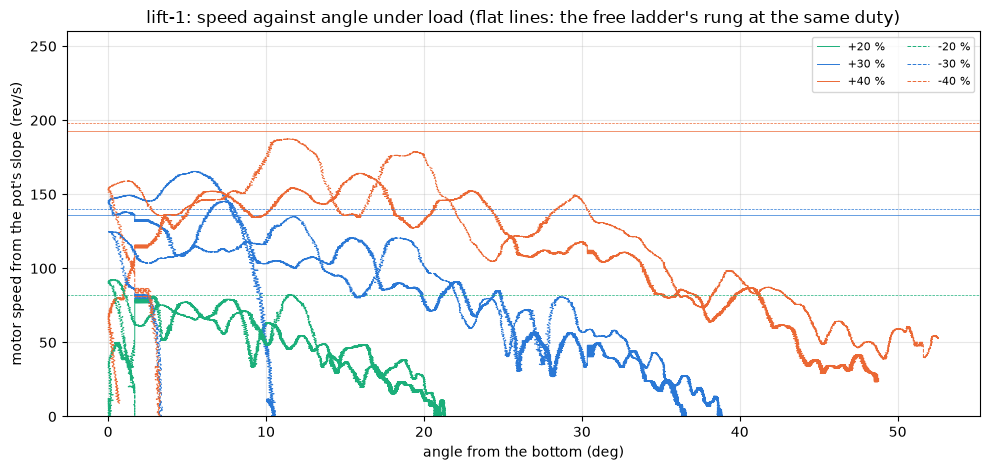

In [47]:
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = {20: GREEN, 30: BLUE, 40: ORANGE}
for _, r in CYCLES[CYCLES["repeat"] == 0].iterrows():
    th, w = LIFT_TRACES[r["k"]]
    c, ls = colors[r["duty_pct"]], "-" if r["side"] > 0 else "--"
    ax.plot(th, w, lw=0.7, color=c, ls=ls,
            label=f"{r['side'] * r['duty_pct']:+d} %")
    free = FREE.get((r["duty_pct"], r["side"]))
    if free:
        ax.axhline(free[0], color=c, lw=0.5, ls=ls)
ax.set_ylim(0, 260)
figures.label(ax, x="angle from the bottom (deg)",
              y="motor speed from the pot's slope (rev/s)",
              title="lift-1: speed against angle under load (flat lines: "
              "the free ladder's rung at the same duty)")
ax.legend(fontsize=8, ncol=2)
figures.finish(fig)

What you are looking at. The motor's speed from the pot's slope against the angle while lifting, the first of each pair, up solid and down dashed, the flat lines the free ladder's rung at the same duty. The first degrees spin through the lash before the arm moves.

The loss grows with the angle, 53 to 56 rev/s at 20 degrees and 81 to 94 at 30 degrees for the up side's 30 and 40 %. The torque curve's prediction of the loss is $R_C (i_w - i_{c,\mathrm{free}}) / K_e$, with $R_C$ the resistance result's construction C value and both currents under construction C. Over the 20 and 30 degree windows it explains 0.79 to 0.89 of the loss on the up side, which loses 7.9 to 12.4 rev/s more than the prediction. On the down side it explains 0.93 to 1.21. There the loss less the prediction is -9.2 to -1.3 rev/s at 30 and 40 % and +2.3 and +5.5 at 20 %. The remainder takes opposite signs on the two sides at 30 and 40 %, which points at a term set by the direction of drive, the brush drop's direction term the candidate, low confidence. The 10 degree windows scatter from 0.68 to 1.44 and are left out of the number.

Lifting through 30 degrees the motor draws 214 to 235 mA, against 271 and 255 mA for the static from-below lines at 30 degrees, a ratio of 0.83 to 0.89. The moving arm draws less current than the one that just stuck, about the size of the lines' intercepts.

In [48]:
def fall_fit(j, tau_h, a, w, al):
    """J alpha + gravity = -T_c sgn(w) - b w by least squares, mN m: j the
    inertia at the output, tau_h gravity's torque at horizontal."""
    X = np.c_[-np.sign(w), -np.radians(w)]
    y = j * np.radians(al) * 1e3 + tau_h * np.sin(np.radians(a))
    coef = np.linalg.lstsq(X, y, rcond=None)[0]
    return coef, np.sqrt(((y - X @ coef) ** 2).mean())

In [49]:
SG_ROWS = 801           # rows, the 40 ms Savitzky-Golay window
FAST_DEG_S = 100        # deg/s, where the EMF and the pot are compared


def fall_row(k):
    _, f = FALL_ROWS[k]
    tf = np.arange(len(f)) / FS
    th = np.asarray(theta_deg(f["pos"], BOTTOM))      # signed
    a = savgol_filter(th, SG_ROWS, 3)
    w = savgol_filter(th, SG_ROWS, 3, deriv=1, delta=1 / FS)    # deg/s
    al = savgol_filter(th, SG_ROWS, 3, deriv=2, delta=1 / FS)   # deg/s2
    w_emf = f["emf_v"].to_numpy() / KE / (2 * np.pi) / GEAR * 360
    first = tf < 1.0
    ip = int(np.argmax(np.abs(w[first])))     # the speed's peak
    mm = (np.abs(w) > FAST_DEG_S) & first
    moving = np.flatnonzero(np.abs(w) > 10)
    stop = int(moving[-1]) if len(moving) else len(w) - 1
    mv = (np.abs(w) > 20) & first & (tf > 0.01)
    coef_c, _ = fall_fit(J_OUT, TAU_COINS, a[mv], w[mv], al[mv])
    coef, rms = fall_fit(J_TOTAL, TAU_H, a[mv], w[mv], al[mv])
    FALL_TRACES[k] = (tf, w, w_emf)
    return {"k": k, "w_peak": w[ip], "theta_peak": a[ip],
            "peak_coins": gravity_coins(a[ip]),
            "emf_ratio": (w_emf[mm].sum() / w[mm].sum()
                          if mm.sum() > 100 else np.nan),
            "coulomb_coins": coef_c[0], "viscous_coins": coef_c[1],
            "coulomb": coef[0], "viscous": coef[1],
            "fit_rms": rms,
            "recoil_deg": np.ptp(th[stop - 2000:stop])
            if stop > 2000 else np.nan,
            "stop_s": (stop + 1) / FS, "end_deg": th[-10000:].mean()}


FALL_TRACES = {}
FALL = CYCLES[["k", "side", "duty_pct", "repeat"]].merge(
    pd.DataFrame([fall_row(k) for k in CYCLES["k"]]), on="k")
show(FALL, n=None)

,k,side,duty_pct,repeat,w_peak,theta_peak,peak_coins,emf_ratio,coulomb_coins,viscous_coins,coulomb,viscous,fit_rms,recoil_deg,stop_s,end_deg
0,0,1,20,0,-84.377,15.911,22.948,NaN,10.186,7.971,12.441,9.423,16.310,1.052,0.458,4.660
1,1,1,20,1,-73.738,15.838,22.846,NaN,20.570,-2.539,24.965,-3.284,12.691,0.797,0.477,5.379
2,2,1,30,0,-160.784,16.148,23.281,1.005,10.737,6.837,12.808,8.289,19.879,1.138,0.637,-0.176
3,3,1,30,1,-165.283,16.376,23.601,0.999,13.841,5.466,16.861,6.486,20.519,0.860,0.581,-0.292
4,4,1,40,0,-232.425,22.681,32.278,1.023,4.564,8.642,5.614,10.365,23.337,0.636,0.718,-4.601
5,5,1,40,1,-240.679,22.765,32.391,1.024,3.058,8.894,3.717,10.700,23.917,0.888,0.684,-4.931
6,6,-1,20,0,94.565,-11.919,17.288,NaN,17.405,1.708,21.261,1.751,21.518,1.760,0.415,-5.944
7,7,-1,20,1,108.286,-18.705,26.844,0.644,14.342,4.630,17.388,5.459,23.310,0.888,0.450,-5.019
8,8,-1,30,0,204.649,-11.652,16.907,0.999,5.404,7.841,7.035,9.206,35.171,1.089,0.643,1.686
9,9,-1,30,1,208.024,-11.797,17.114,1.000,4.483,8.079,5.494,9.677,34.597,1.089,0.936,2.178


In [50]:
EMF_R = FALL["emf_ratio"].dropna()
print(f"EMF / Ke / N over the pot's speed above {FAST_DEG_S} deg/s: "
      f"{EMF_R.mean():.3f} +/- {EMF_R.std(ddof=1):.3f} (n {len(EMF_R)})")
FALL["peak_mn_m"] = FALL["peak_coins"] * SCALE   # gravity, exact
for _, r in FALL.iterrows():
    print(f"   {int(r['side'] * r['duty_pct']):+d} %: friction at the "
          f"speed peak {r['peak_mn_m']:.1f} mN m at "
          f"{abs(r['w_peak']):.0f} deg/s")
COULOMB, VISCOUS = FALL["coulomb"], FALL["viscous"]   # absolute
cc, vc = FALL["coulomb_coins"], FALL["viscous_coins"]
cm, cs = COULOMB.mean(), COULOMB.std(ddof=1)
vm, vs = VISCOUS.mean(), VISCOUS.std(ddof=1)
print(f"coins-scale: Coulomb {cc.mean():.1f} +/- {cc.std(ddof=1):.1f} mN m"
      f", viscous {vc.mean():.2f} +/- {vc.std(ddof=1):.2f} mN m s/rad")
print(f"absolute: Coulomb {cm:.1f} +/- {cs:.1f} mN m, viscous {vm:.2f} "
      f"+/- {vs:.2f} mN m s/rad, fit rms {FALL['fit_rms'].min():.0f} to "
      f"{FALL['fit_rms'].max():.0f} mN m")
print(f"viscous at the motor {vm / GEAR ** 2 * 1e3:.3f} uN m s/rad")
RECOIL = FALL["recoil_deg"]
print(f"recoil after the stop {RECOIL.min():.2f} to {RECOIL.max():.2f} "
      f"deg, mean {RECOIL.mean():.2f} (pot-table lash_hand "
      f"{LASH_HAND:.2f}); falls end "
      f"{FALL['end_deg'].abs().min():.1f} to "
      f"{FALL['end_deg'].abs().max():.1f} deg out, stop after "
      f"{FALL['stop_s'].min():.2f} to {FALL['stop_s'].max():.2f} s")

EMF / Ke / N over the pot's speed above 100 deg/s: 0.966 +/- 0.121 (n 9)
   +20 %: friction at the speed peak 27.6 mN m at 84 deg/s
   +20 %: friction at the speed peak 27.5 mN m at 74 deg/s
   +30 %: friction at the speed peak 28.0 mN m at 161 deg/s
   +30 %: friction at the speed peak 28.4 mN m at 165 deg/s
   +40 %: friction at the speed peak 38.8 mN m at 232 deg/s
   +40 %: friction at the speed peak 39.0 mN m at 241 deg/s
   -20 %: friction at the speed peak 20.8 mN m at 95 deg/s
   -20 %: friction at the speed peak 32.3 mN m at 108 deg/s
   -30 %: friction at the speed peak 20.3 mN m at 205 deg/s
   -30 %: friction at the speed peak 20.6 mN m at 208 deg/s
   -40 %: friction at the speed peak 48.1 mN m at 295 deg/s
   -40 %: friction at the speed peak 49.2 mN m at 293 deg/s
coins-scale: Coulomb 11.3 +/- 5.8 mN m, viscous 5.50 +/- 3.37 mN m s/rad
absolute: Coulomb 13.8 +/- 7.0 mN m, viscous 6.51 +/- 4.11 mN m s/rad, fit rms 13 to 35 mN m
viscous at the motor 0.069 uN m s/rad
recoil

In [51]:
rep = LIFT.merge(FALL[["k", "end_deg"]], on="k").groupby(
    ["side", "duty_pct"]).agg(w10=("w_10", np.ptp), top=("theta_top",
                                                          np.ptp),
                              end=("end_deg", np.ptp))
show(rep.reset_index(), n=None)
REPEAT = rep

,side,duty_pct,w10,top,end
0,-1,20,3.248,1.826,0.925
1,-1,30,2.217,0.149,0.492
2,-1,40,63.920,0.759,0.308
3,1,20,1.834,0.226,0.719
4,1,30,4.962,0.424,0.116
5,1,40,5.915,0.385,0.329


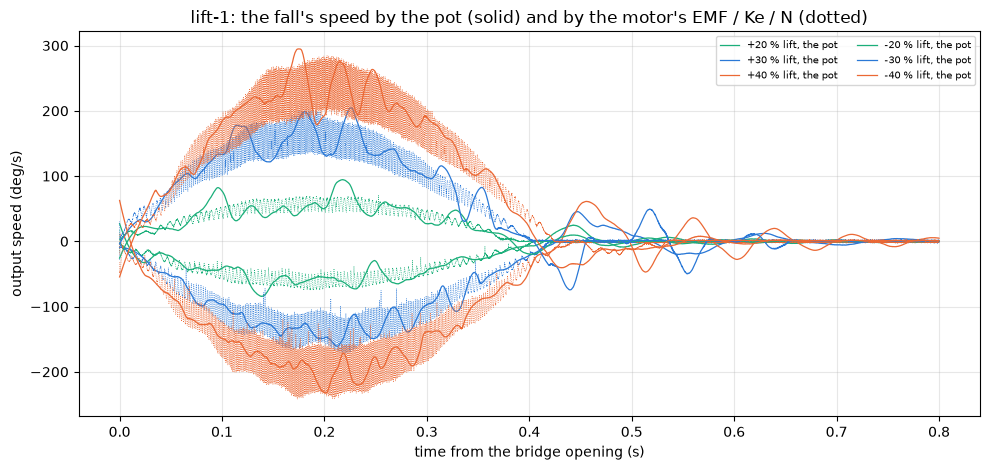

In [52]:
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = {20: GREEN, 30: BLUE, 40: ORANGE}
for _, r in CYCLES[CYCLES["repeat"] == 0].iterrows():
    tf, w, w_emf = FALL_TRACES[r["k"]]
    m = tf < 0.8
    c = colors[r["duty_pct"]]
    ax.plot(tf[m], w[m], lw=0.9, color=c,
            label=f"{r['side'] * r['duty_pct']:+d} % lift, the pot")
    ax.plot(tf[m], w_emf[m], lw=0.5, ls=":", color=c)
figures.label(ax, x="time from the bridge opening (s)",
              y="output speed (deg/s)",
              title="lift-1: the fall's speed by the pot (solid) and by "
              "the motor's EMF / Ke / N (dotted)")
ax.legend(fontsize=7, ncol=2)
figures.finish(fig)

What you are looking at. The fall's output speed through the pot (solid) and through the motor's EMF over Ke and N (dotted), the first of each pair. The two agree through each fall, and the EMF drops to zero at the stop.

From 21 to 54 degrees the arm falls and stops 0.42 to 0.94 s after the bridge opens, the -30 % repeat k9 the 0.94. The 20 % falls stop on their own side, the 30 % falls at the bottom or just past it, and the 40 % falls on the far side. Above 100 deg/s the EMF over Ke and N tracks the pot's speed at 0.966 +/- 0.121 over 9 falls, so the train back-drives the motor at N times the output with no slip.

At the speed's peak the acceleration is zero and gravity's torque is the friction. Per fall it reads 27.6 and 27.5 mN m at 84 and 74 deg/s (+20 %), 28.0 and 28.4 at 161 and 165 (+30 %), 38.8 and 39.0 at 232 and 241 (+40 %), 20.8 and 32.3 at 95 and 108 (-20 %), 20.3 and 20.6 at 205 and 208 (-30 %) and 48.1 and 49.2 at 295 and 293 (-40 %). It grows with speed. A regression through each fall, $J \alpha + \tau \sin\theta = -T_c \,\mathrm{sgn}(\omega) - b \omega$, with $\tau$ here the torque at horizontal, $T_c$ the Coulomb term, $b$ the viscous one and $\omega$ ("omega") the speed, with the same absolute gravity and inertia, gives $T_c$ 13.8 +/- 7.0 mN m and $b$ 6.51 +/- 4.11 mN m s/rad, 0.069 uN m s/rad at the motor, low confidence, with a fit rms of 13 to 35 mN m.

After the stop the pot recoils 0.64 to 2.46 degrees, mean 1.24, while the EMF reads zero. That is the output turning back inside the lash with the motor still, and it matches the pot table's hand rock of 1.24 degrees. The two repeats agree to 0.12 to 0.93 degrees at the fall's end and 0.15 to 1.83 degrees at the top, and to 1.8 to 5.9 rev/s at 10 degrees, except the -40 % pair, which started at 1.7 and 7.1 degrees.

## 8. The stall current per duty

Every settled rung of 6 % or more with a valid window, the three stop rungs included since they are stalls too, both as read and under construction C.

In [53]:
ST = R[R["stalled"] & (R["window_valid"] > 0.99)
       & (R["duty_pct"] >= 6)].copy()
FA = results.fit_line(ST["v_a_v"], ST["i_crest_a"])   # as read
FC = results.fit_line(ST["i_w_a"], ST["v_c_v"])       # construction C
ST["resid_mv"] = FC["resid"] * 1e3
print(f"as read: i = {FA['intercept'] * 1e3:+.1f} mA + "
      f"{FA['slope'] * 1e3:.1f} mA/V x D V_on, 1/slope "
      f"{1 / FA['slope']:.3f} ohm, rms {FA['rms'] * 1e3:.1f} mA, n "
      f"{FA['n']}")
V_ON = ST["v_on_v"].mean()
print(f"   = {FA['slope'] * V_ON / 100 * 1e3:.2f} mA per % at V_on "
      f"{V_ON:.2f} V; the resistance result's as-read line predicts "
      f"{1e3 / R_STOP_A:.1f} mA/V, {-V0_STOP_A / R_STOP_A * 1e3:+.1f} mA")
print(f"   the warm hold draws {(1 - FA['slope'] * R_STOP_A) * 100:.1f} % "
      f"under the cold line's slope")
print(f"C: v_c = {FC['intercept'] * 1e3:+.0f} mV + {FC['slope']:.3f} +/- "
      f"{FC['slope_se']:.3f} ohm x i_w, rms {FC['rms'] * 1e3:.0f} mV; "
      f"resistance C {R_C:.3f} ohm, {V0_C * 1e3:+.0f} mV")
for side in (1, -1):
    f = results.fit_line(ST[ST["side"] == side]["i_w_a"],
                         ST[ST["side"] == side]["v_c_v"])
    print(f"   side {side:+d}: {f['slope']:.3f} +/- {f['slope_se']:.3f} "
          f"ohm, {f['intercept'] * 1e3:+.0f} mV, n {f['n']}")

as read: i = +15.3 mA + 208.8 mA/V x D V_on, 1/slope 4.789 ohm, rms 4.5 mA, n 41
   = 10.00 mA per % at V_on 4.79 V; the resistance result's as-read line predicts 228.4 mA/V, -2.5 mA
   the warm hold draws 8.6 % under the cold line's slope
C: v_c = -82 mV + 4.538 +/- 0.032 ohm x i_w, rms 26 mV; resistance C 4.177 ohm, +31 mV
   side +1: 4.564 +/- 0.050 ohm, -94 mV, n 20
   side -1: 4.517 +/- 0.041 ohm, -71 mV, n 21


In [54]:
BAND = (16, 46)         # % of duty, the middle of the stall line
mid = ST[ST["duty_pct"].between(*BAND)]
RESID_BAND = mid["resid_mv"].abs().max()
TREND = results.fit_line(mid["duty_pct"], mid["resid_mv"])
TREND_SIGMA = abs(TREND["slope"] / TREND["slope_se"])
print(f"{BAND[0]} to {BAND[1]} %: |residual| at most {RESID_BAND:.1f} mV "
      f"(n {len(mid)}); trend {TREND['slope']:+.3f} +/- "
      f"{TREND['slope_se']:.3f} mV per %, {TREND_SIGMA:.1f} sigma")
for lo, hi in ((6, 14), (50, 54)):
    x = ST[ST["duty_pct"].between(lo, hi)]["resid_mv"]
    print(f"{lo} to {hi} %: residuals {x.min():+.0f} to {x.max():+.0f} mV"
          f", mean {x.mean():+.0f} (n {len(x)})")

16 to 46 %: |residual| at most 37.9 mV (n 29); trend +0.425 +/- 0.355 mV per %, 1.2 sigma
6 to 14 %: residuals -3 to +38 mV, mean +21 (n 9)
50 to 54 %: residuals +25 to +79 mV, mean +50 (n 3)


As read, the 41 rungs sit on one line, $i = 15.3 \,\mathrm{mA} + 208.8 \,\mathrm{mA/V} \times D V_\mathrm{on}$, rms 4.5 mA, 1 / slope 4.789 ohm. At 5 V that is 10.00 mA per % of duty after a 3 s hold. The resistance result's as-read line predicts 228.4 mA/V, so the warm hold draws 8.6 % under the cold line's slope.

Under construction C the line is $V_c = -82 \,\mathrm{mV} + 4.538 \,\Omega \times i_w$, +/- 0.032 ohm, rms 26 mV, the sides 4.564 and 4.517 ohm. Over 16 to 46 % its residuals lie within +/- 37.9 mV with no trend in duty, 1.2 sigma. They bow up at both ends, a mean of +21 mV over 6 to 14 % and +50 mV over 50 to 54 %.

In [55]:
X3 = np.c_[np.ones(len(ST)), ST["i_w_a"], ST["i_w_a"] ** 3]
CUBIC, *_ = np.linalg.lstsq(X3, ST["v_c_v"], rcond=None)
res3 = ST["v_c_v"] - X3 @ CUBIC
cov3 = (res3 ** 2).sum() / (len(ST) - 3) * np.linalg.inv(X3.T @ X3)
CUBIC_SE = np.sqrt(np.diag(cov3))
V0_3, R0_3, C_3 = CUBIC
WARM_CUBIC = C_3 * 0.5 ** 2 / R0_3      # share of R0 at 0.5 A
print(f"v_c = V0 + R0 i + c i^3: V0 {V0_3 * 1e3:+.0f} +/- "
      f"{CUBIC_SE[0] * 1e3:.0f} mV, R0 {R0_3:.3f} +/- {CUBIC_SE[1]:.3f} "
      f"ohm, c {C_3:.2f} +/- {CUBIC_SE[2]:.2f} ohm/A^2; rms "
      f"{np.sqrt((res3 ** 2).mean()) * 1e3:.0f} mV")
print(f"at 0.5 A the cubic term is {WARM_CUBIC * 100:.1f} % of R0, "
      f"{WARM_CUBIC / ALPHA_CU:.0f} C of copper")

v_c = V0 + R0 i + c i^3: V0 -21 +/- 7 mV, R0 4.110 +/- 0.041 ohm, c 1.64 +/- 0.14 ohm/A^2; rms 12 mV
at 0.5 A the cubic term is 10.0 % of R0, 26 C of copper


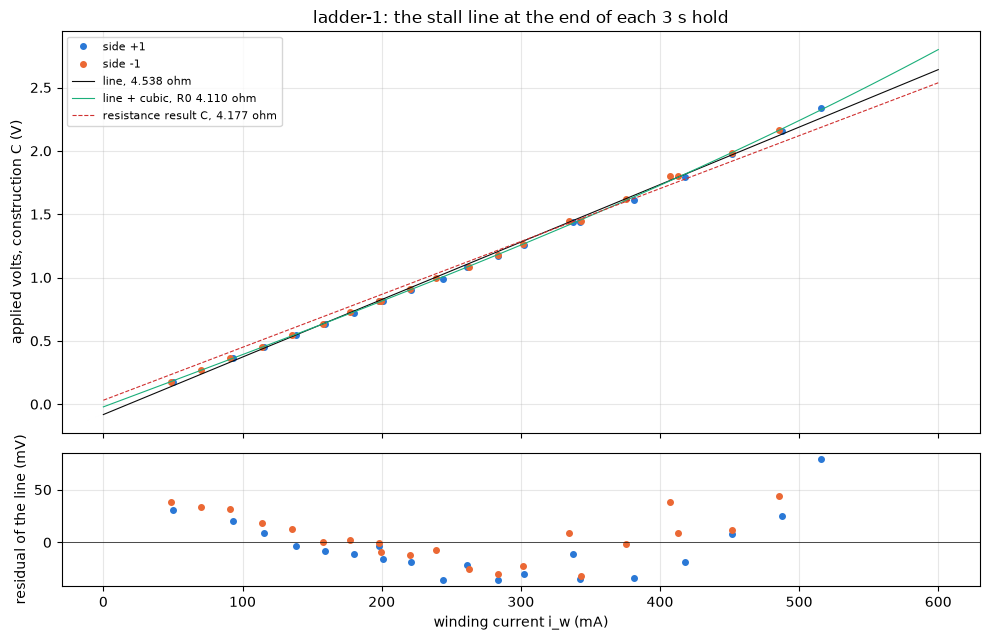

In [56]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
xx = np.linspace(0, 0.6, 50)
for side, color in ((1, BLUE), (-1, ORANGE)):
    d = ST[ST["side"] == side]
    ax1.plot(d["i_w_a"] * 1e3, d["v_c_v"], "o", ms=4, color=color,
             label=f"side {side:+d}")
    ax2.plot(d["i_w_a"] * 1e3, d["resid_mv"], "o", ms=4, color=color)
ax1.plot(xx * 1e3, FC["intercept"] + FC["slope"] * xx, color=INK, lw=0.8,
         label=f"line, {FC['slope']:.3f} ohm")
ax1.plot(xx * 1e3, V0_3 + R0_3 * xx + C_3 * xx ** 3, color=GREEN, lw=0.8,
         label=f"line + cubic, R0 {R0_3:.3f} ohm")
ax1.plot(xx * 1e3, V0_C + R_C * xx, **figures.HIGHLIGHT_STYLE,
         label=f"resistance result C, {R_C:.3f} ohm")
ax2.axhline(0, color=INK, lw=0.5)
figures.label(ax1, y="applied volts, construction C (V)",
              title="ladder-1: the stall line at the end of each 3 s hold")
figures.label(ax2, x="winding current i_w (mA)",
              y="residual of the line (mV)")
ax1.legend(fontsize=8)
figures.finish(fig)

What you are looking at. The applied volts under construction C against the winding current at the end of each hold (top), the straight line, the line with a cubic term and the resistance result's C line, and the straight line's residuals (bottom).

A term $c i^3$ for warming over the fixed 3 s hold takes the rms to 12 mV with $R_0$ 4.110 +/- 0.041 ohm, $V_0$ -21 +/- 7 mV and $c$ 1.64 +/- 0.14 ohm/A^2, 10.0 % of $R_0$ at 0.5 A. Against the resistance result's 4.177 ohm and +31 mV, the end-of-hold line is steeper and the cubic's cold $R_0$ is lower. Two readings of the bow stay open. One is warming through the hold. The other is the crest term $g$ taken below the duty band it was measured over, where it is a large share of a small current.

bottom-1  26.26 -> 26.39 C over minutes 0 to 3; rail probe 4.985 V sd 0.011
ladder-1  26.46 -> 26.84 C over minutes 3 to 43; rail probe 4.988 V sd 0.008
lift-1    26.72 -> 26.97 C over minutes 44 to 53; rail probe 4.987 V sd 0.009
steps-1   26.99 -> 27.08 C over minutes 54 to 63; rail probe 4.986 V sd 0.008
sitting: 26.26 -> 27.08 C, +0.82 C over 63 min; ladder up side 26.35 C, down side 26.58 C


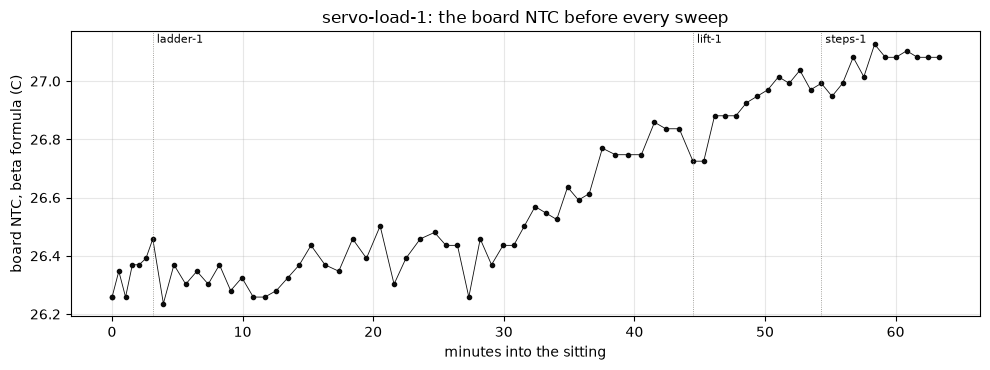

In [57]:
P = PROBES.copy()
P["minutes"] = (P["t_host"] - P["t_host"].min()) / 60
blocks = ("bottom-1", "ladder-1", "lift-1", "steps-1")
for blk in blocks:
    d = P[P["folder"].str.startswith(blk)]
    print(f"{blk:9s} {d['ntc_c'].iloc[0]:.2f} -> {d['ntc_c'].iloc[-1]:.2f}"
          f" C over minutes {d['minutes'].iloc[0]:.0f} to "
          f"{d['minutes'].iloc[-1]:.0f}; rail probe {d['rail_v'].mean():.3f}"
          f" V sd {d['rail_v'].std():.3f}")
NTC_OPEN, NTC_CLOSE = P["ntc_c"].iloc[0], P["ntc_c"].iloc[-1]
print(f"sitting: {NTC_OPEN:.2f} -> {NTC_CLOSE:.2f} C, "
      f"{NTC_CLOSE - NTC_OPEN:+.2f} C over {P['minutes'].max():.0f} min; "
      f"ladder up side {R[R['side'] == 1]['ntc_c'].mean():.2f} C, down "
      f"side {R[R['side'] == -1]['ntc_c'].mean():.2f} C")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(P["minutes"], P["ntc_c"], "o-", ms=3, color=INK, lw=0.6)
for blk in blocks[1:]:
    t0 = P[P["folder"].str.startswith(blk)]["minutes"].iloc[0]
    ax.axvline(t0, **figures.EDGE_STYLE)
    ax.text(t0, NTC_CLOSE + 0.05, f" {blk}", fontsize=8)
figures.label(ax, x="minutes into the sitting",
              y="board NTC, beta formula (C)",
              title="servo-load-1: the board NTC before every sweep")
figures.finish(fig)

What you are looking at. The board NTC at each probe through the sitting, the blocks marked. It read 26.26 C at the first probe and 27.08 C at the last, +0.82 C over 63 minutes. The ladder's up side ran at 26.35 C on average and its down side, run after it, at 26.58 C.

In [58]:
start = []
for _, r in R.iterrows():
    df, _ = load_sweep(DATA / "ladder-1" / f"ladder/{int(r['k'])}")
    s1 = df[df["seg"] == sorted(df["seg"].unique())[1]].reset_index()
    e = tel.drive_start(s1)                 # the duty's first row
    early = s1.iloc[e + 40:e + 100]          # 2 to 5 ms after the edge
    start.append({"k": r["k"], "i_start_a": early["i_a"].mean(),
                  "move_5ms": s1["pos"].iloc[e + 100] - s1["pos"].iloc[e]})
W = R.merge(pd.DataFrame(start), on="k")
W["start_over_end"] = W["i_start_a"] / W["i_crest_a"]
below = W[(W["approach"] == "below") & (W["duty_pct"] >= 6)]
for name, d in (("moved", below[below["moved"]]),
                ("never moved", below[~below["moved"]])):
    x = (1 - d["start_over_end"]) * 100
    print(f"{name:11s}: start under end by {x.min():+.1f} to "
          f"{x.max():+.1f} % (n {len(d)})")
print("over end: " + ", ".join(
    f"k{int(r['k'])} {r['start_over_end']:.4f}"
    for _, r in below[below["start_over_end"] >= 1].iterrows()))

moved      : start under end by -0.1 to +14.6 % (n 33)
never moved: start under end by +3.0 to +7.0 % (n 4)
over end: k28 1.0007


In [59]:
C0 = W[(W["duty_pct"] >= 6) & (W["move_5ms"].abs() <= 2)].copy()
C0["v_c0"], C0["i_w0"] = construction_c(
    C0["D"].to_numpy(), C0["v_on_v"].to_numpy(), C0["i_start_a"].to_numpy())
F0 = results.fit_line(C0["i_w0"], C0["v_c0"])
print(f"start currents, construction C: {F0['slope']:.3f} +/- "
      f"{F0['slope_se']:.3f} ohm, {F0['intercept'] * 1e3:+.0f} mV, rms "
      f"{F0['rms'] * 1e3:.0f} mV, n {F0['n']}")

start currents, construction C: 4.774 +/- 0.120 ohm, -34 mV, rms 82 mV, n 28


The winding as its own thermometer. The current 2 to 5 ms into each hold, with the copper at its rest temperature, against the current at its end, 3.1 s later, would give the warming over the hold. It does not work here. The start reads under the end by -0.1 to +14.6 % at every duty that moved the arm but one, the 14 % down rung k28, equal at 1.0007, and by 3.0 to 7.0 % on the four rungs that never moved. The motor spins through its lash at the start of a hold that moves the arm, and its EMF holds the current down while it does. The start currents' own line has an rms of 82 mV.

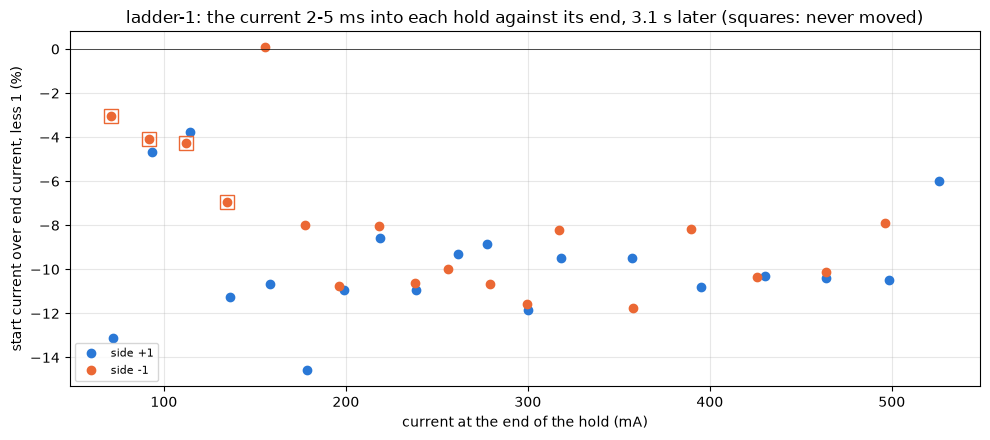

In [60]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for side, color in ((1, BLUE), (-1, ORANGE)):
    d = below[below["side"] == side]
    ax.plot(d["i_crest_a"] * 1e3, (d["start_over_end"] - 1) * 100,
            "o", color=color, label=f"side {side:+d}")
    n = d[~d["moved"]]
    ax.plot(n["i_crest_a"] * 1e3, (n["start_over_end"] - 1) * 100,
            "s", mfc="none", ms=10, color=color)
ax.axhline(0, color=INK, lw=0.5)
figures.label(ax, x="current at the end of the hold (mA)",
              y="start current over end current, less 1 (%)",
              title="ladder-1: the current 2-5 ms into each hold against "
              "its end, 3.1 s later (squares: never moved)")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. Each hold's start current over its end current, less 1, against the end current, the squares the rungs that never moved. Almost every hold that moved the arm starts low, the lash spin, so the figure shows that effect and not the warming.

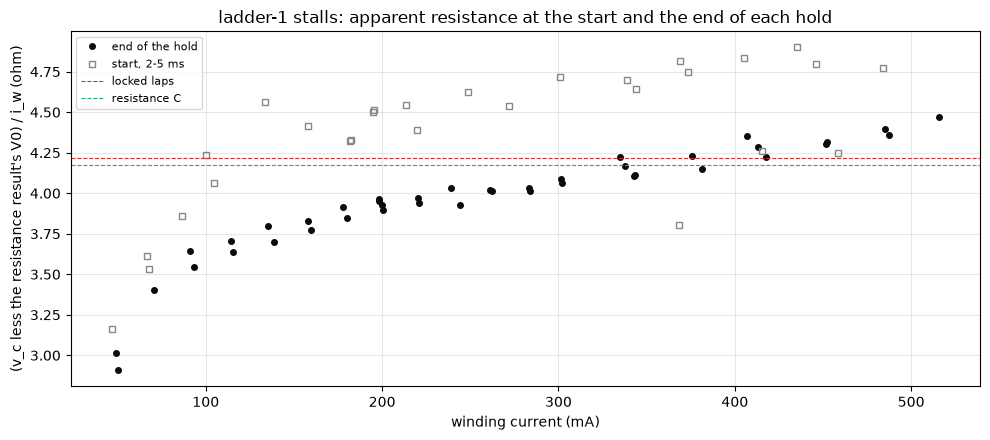

In [61]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(ST["i_w_a"] * 1e3, (ST["v_c_v"] - V0_C) / ST["i_w_a"], "o",
        ms=4, color=INK, label="end of the hold")
ax.plot(C0["i_w0"] * 1e3, (C0["v_c0"] - V0_C) / C0["i_w0"], "s",
        ms=4, mfc="none", color=MUTED, label="start, 2-5 ms")
ax.axhline(R_LOCKED, **figures.HIGHLIGHT_STYLE, label="locked laps")
ax.axhline(R_C, color=GREEN, lw=0.8, ls="--", label="resistance C")
figures.label(ax, x="winding current (mA)",
              y="(v_c less the resistance result's V0) / i_w (ohm)",
              title="ladder-1 stalls: apparent resistance at the start and "
              "the end of each hold")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. The apparent resistance at the start and at the end of each hold, the resistance result's V0 taken off, against the locked laps' 4.219 ohm and construction C's 4.177. The end of a hold reads high and the starts scatter wide.

In [62]:
# the resistance notebook's meter holds as the analysis note reads them:
# the crest fell about 2.2 % over 2.5 s at about 0.37 A
METER_FALL, METER_A, METER_S = 0.022, 0.37, 2.5
HOLD_A, HOLD_S = 0.5, 3.0              # the ladder's top holds
meter_scaled = METER_FALL * (HOLD_A / METER_A) ** 2 * HOLD_S / METER_S
print(f"meter fall {METER_FALL * 100:.1f} % at {METER_A} A over {METER_S} "
      f"s, scaled by i^2 and time to {HOLD_A} A over {HOLD_S} s: "
      f"{meter_scaled * 100:.1f} % = {meter_scaled / ALPHA_CU:.0f} C; the "
      f"cubic {WARM_CUBIC * 100:.1f} % = {WARM_CUBIC / ALPHA_CU:.0f} C; "
      f"heating tau {TAU_HEAT_S:.1f} s")
m = R[(R["approach"] == "below") & R["duty_pct"].between(14, 46)]
p = m.pivot_table(index="duty_pct", columns="side", values="i_crest_a")
SIDE_I = (p[-1] / p[1]).dropna()
R_FWD = RES["r_term_by_direction_ohm_fwd"]["value"]
R_REV = RES["r_term_by_direction_ohm_rev"]["value"]
print(f"end current down over up, 14 to 46 %: {SIDE_I.mean():.4f} sd "
      f"{SIDE_I.std(ddof=1):.4f} = {(1 / SIDE_I.mean() - 1) / ALPHA_CU:+.1f}"
      f" C as warming; locked laps R_fwd / R_rev {R_FWD / R_REV:.4f}")

meter fall 2.2 % at 0.37 A over 2.5 s, scaled by i^2 and time to 0.5 A over 3.0 s: 4.8 % = 12 C; the cubic 10.0 % = 26 C; heating tau 3.4 s
end current down over up, 14 to 46 %: 0.9937 sd 0.0080 = +1.6 C as warming; locked laps R_fwd / R_rev 1.0045


What is left for the warming. The cubic says 10.0 % at 0.5 A, 26 C of copper. The resistance notebook's meter holds fell about 2.2 % over 2.5 s at about 0.37 A, which scales by $i^2$ and time to 4.8 % at 0.5 A over 3 s, 12 C, against a heating time constant of 3.4 s. So a 3 s hold at 0.5 A warms the winding by somewhere from 12 to 26 C, low confidence. The design line holds either way. A servo holding a load at 5 V draws 10.00 mA per % after 3 s and 15.3 mA at zero duty by the line, under the cold line, so a stall threshold set from the cold line sits above a warm hold's current.

Warming does not explain the side split. The down side's end currents at matched duty are 0.9937 of the up side's, sd 0.0080, 1.6 C if read as warming, and the locked laps split the two directions by 1.0045. Either way it is current, and the split in question is torque per amp.

## 9. The pot under load

The push block did not run, so what this sitting gives is bounds.

In [63]:
st = STEPS[STEPS["edge"] == "step"].dropna(subset=["d_theta"])
up5, dn5 = st[st["step_pct"] > 0], st[st["step_pct"] < 0]
for name, x in (("+5 %", up5), ("-5 %", dn5)):
    print(f"{name}: pot moved {x['d_theta'].round(2).tolist()} deg, mean "
          f"{x['d_theta'].mean():+.3f} se "
          f"{x['d_theta'].std(ddof=1) / np.sqrt(len(x)):.3f}")
POT_DIFF = up5["d_theta"].mean() - dn5["d_theta"].mean()
POT_SE = np.hypot(up5["d_theta"].std(ddof=1) / np.sqrt(len(up5)),
                  dn5["d_theta"].std(ddof=1) / np.sqrt(len(dn5)))
POT_BOUND = st["d_theta"].abs().max()
print(f"(+5) less (-5): {POT_DIFF:+.3f} +/- {POT_SE:.3f} deg, "
      f"{abs(POT_DIFF / POT_SE):.1f} sigma; bound {POT_BOUND:.2f} deg")
rest = USE
fn = results.fit_line(rest["tau_mn_m"], rest["rest_sd"])
print(f"pot sd at rest {rest['rest_sd'].mean():.2f} counts, against the "
      f"held torque {fn['slope']:+.4f} +/- {fn['slope_se']:.4f} counts per"
      f" mN m ({abs(fn['slope'] / fn['slope_se']):.1f} sigma); up side "
      f"{rest[rest['side'] == 1]['rest_sd'].mean():.2f}, down "
      f"{rest[rest['side'] == -1]['rest_sd'].mean():.2f}")
smooth = POT["table_smooth_rms_counts"]["value"]
print(f"the table's smooth part {smooth:.0f} counts rms, "
      f"{smooth / POT['pot_scale_counts_per_deg']['value']:.1f} deg; the "
      f"bottom's bracket {abs(theta_deg(BOTTOM_HI, BOTTOM_LO)):.1f} deg")

+5 %: pot moved [0.06, -0.15, -0.33, 0.05, -0.09] deg, mean -0.094 se 0.073
-5 %: pot moved [-0.13, 0.05, 0.07, 0.0, 0.06] deg, mean +0.012 se 0.037
(+5) less (-5): -0.106 +/- 0.082 deg, 1.3 sigma; bound 0.33 deg
pot sd at rest 1.04 counts, against the held torque +0.0008 +/- 0.0023 counts per mN m (0.4 sigma); up side 1.28, down 0.74
the table's smooth part 12 counts rms, 0.7 deg; the bottom's bracket 0.9 deg


Under the +/- 5 % steps the output stayed still while the current changed by 47 to 53 mA. The pot moved -0.094 degrees on average for +5 % and +0.012 for -5 %, a difference of -0.106 +/- 0.082 degrees, 1.3 sigma, not a finding. A torque-to-reading coupling is at most 0.33 degrees per step of 5 %. The pot's sd at rest is 1.04 counts and does not change with the held torque, 0.4 sigma. It is 1.28 counts on the up side and 0.74 on the down, a split this sitting leaves open.

The recoil after every fall, 1.24 degrees with zero EMF, is the lash seen from the pot, as the pot table's hand rock found. A radial-load term that turns with the arm is not separated here from the table's own smooth part, 12 counts rms, 0.7 degrees, or from the bottom's 0.9 degree bracket. The push block is the measurement.

## 10. The end-stop rungs, the capture and what comes next

### The rungs past the soft limits

The ladder's top was 75 degrees, and both sides ran one rung past horizontal. Three rungs rested against something past the soft limits for 3 s with the duty never folded, since the experiment image's open-loop hold has no soft-limit guard.

In [64]:
STOPS = R[R["past_soft"]].copy()
STOPS["to_end"] = np.where(STOPS["rest_pos"] > 2048,
                           SERVO_ENDS[1] - STOPS["rest_pos"],
                           STOPS["rest_pos"] - SERVO_ENDS[0])
show(STOPS[["k", "side", "duty_pct", "approach", "rest_pos", "to_end",
            "rest_range", "i_crest_a", "duty_ticks", "duty_ticks_cmd"]],
     n=None)
print(f"soft limits {SOFT}, free ends {SERVO_ENDS}; lap cap "
      f"{SERVO.lap_cap_a} A, held-stall cap {SERVO.stop_hold_a} A; over the"
      f" lap cap: {int((STOPS['i_crest_a'] > SERVO.lap_cap_a).sum())} of "
      f"{len(STOPS)}")

,k,side,duty_pct,approach,rest_pos,to_end,rest_range,i_crest_a,duty_ticks,duty_ticks_cmd
19,19,1,54,below,3753.000,39.000,8,0.526,648.000,648
41,41,-1,50,below,196.000,114.000,3,0.496,600.000,600
44,44,-1,42,above,247.000,165.000,2,0.420,504.000,504


soft limits (314, 3560), free ends (82, 3792); lap cap 0.45 A, held-stall cap 0.5 A; over the lap cap: 2 of 3


k19 at 54 % rested at 3753 counts, 39 from the high free end, at 0.526 A. k41 at 50 % rested at 196, 114 from the low free end, at 0.496 A. k44 at 42 % from above rested at 247, 165 from it, at 0.420 A. Whether each sat on the hard stop or in the pot's end region, the data do not say. Two of the three ran above the README's 0.45 A lap cap for 3 s into the plastic output stopper, so the free ends want a re-read at the stops. Sitting 2 ran before one.

In [65]:
import json  # noqa: E402

metas = [json.loads(p.read_text()) for p in sorted(DATA.rglob("meta.json"))]
dropped = sum(m["rows_dropped"] for m in metas)
limit = {m["drive"]["current_limit_counts"] for m in metas}
peak = 0
for _, r in R.iterrows():
    df, _ = load_sweep(DATA / "ladder-1" / f"ladder/{int(r['k'])}")
    peak = max(peak, (df["current_raw"] - df["zero_i"]).abs().max())
rails = PROBES["rail_v"]
print(f"{len(metas)} sweeps, rows dropped {dropped}; current limit "
      f"{limit} counts, the ladder's largest current over its zero "
      f"{peak:.0f} counts; rail probe {rails.mean():.3f} +/- "
      f"{rails.std():.3f} V")

75 sweeps, rows dropped 0; current limit {942} counts, the ladder's largest current over its zero 653 counts; rail probe 4.987 +/- 0.008 V


### The capture itself

All 75 sweeps dropped no rows. The current limit stayed at 942 counts and the ladder's largest current over its zero was 653, so the limit never engaged. The rail probe read 4.987 +/- 0.008 V before every sweep.

- The bottom's 12 % for 1.5 s lifts the arm only to 9.5 degrees, inside the static band, so no drop happened. The lifts' falls from 21 degrees did fall, so a drop needs a start past about 20 degrees.
- The ladder's from-above step of 6 % sits inside the deadband, so the arm never fell after the step down.
- The ladder's top of 75 degrees let each side run one rung past horizontal into the stops.
- The steps of 5 % sit inside the deadband, so the block recorded current steps and no motion.
- The pot table stops short of the ladder's top rests on both sides and of the guards, so the end slope carries the angle there.
- The 4 % rungs sit under the current window floor and the 6 % rungs under the tap floor.
- The seek to the start leaves the arm at a friction rest anywhere from -12.5 to +13.2 degrees, so the low rungs depend on which side the arm sat.
- The up side ran first and the down side after it, so direction and time are confounded in the ladder.

### What stages 4 to 7 read from here

- The hold's deadband. A constant-duty hold does not move the output inside at least +/- 5 % of duty, 47 to 53 mA at the motor, and taking 6 % off a held duty did not let the arm fall at any rest tried. These are lower bounds.
- The stall line. Hot, after a 3 s hold at 5 V, 10.00 mA per % of duty with 15.3 mA at zero, 4.789 ohm as read. Cold, the resistance result's line, whose slope the hot line sits 8.6 % under. A stall fault set from the cold line sits above a warm hold's current.
- Kt through the gears at a rising stall, 215.8 (210.7 to 220.0) mN m/A up and 234.3 (228.1 to 242.7) down, 222.9 pooled, 0.624 of $K_e N$, absolute with the arm weighed.
- The friction bounds. The back-driven train holds at least 16.6 mN m with the bridge open, the friction band under load is at least 13.8 to 16.6 mN m, and a fall starts against 33.4 +/- 4.7 mN m.
- The fall back-drives the motor with no slip, so the EMF reads the output speed through Ke and N whenever the arm falls.

### The next sitting's plan

Sitting 2 runs on the plan as committed on the `load-plan-2` branch and documented in the README's `load` section.

- The bottom lifts at 20 % for 1 s, so the arm starts past the static band. The lifts' falls from 21 degrees did fall.
- The ladder alternates the sides at each duty, stops a side once a rest passes 60 degrees and leaves out a rung the last two rests predict past 80, so no hold runs to a stop.
- The from-above rungs go 16 % over, then walk down a stair of 2 % every 300 ms onto the duty.
- The steps go 10, 15 and 20 % at two angles a side, so the first size that moves the arm brackets the band.
- The coins sit in the inner cup pair, 41.57 mm out, a second torque that checks the arm's term and the deadband.

### Open discrepancies

1. The stall currents at the end of a 3 s hold sit under the resistance result's cold line, with a bow a warming term fits. Warming and a mis-scaled crest term $g$ at low duty both fit it. A locked hold of 3 s at 25 and 45 % streamed whole gives the current's decay with time directly, and the DC ammeter at 6 to 12 % duty extends the $g$ band below 16 %.
2. Kt through the gears by direction, 215.8 against 234.3 mN m/A, 2.6 sigma with every rung and 1.6 table-only, with the torque-per-amp ratio moving from 1.014 to 1.080 across the three bottoms. Extending the pot table over the full guard span, fixing the bottom, alternating the sides at each duty and repeating each rung twice separate the table's ends, the bottom and the commutation scatter from the train. A real train asymmetry survives all four.
3. The friction band and the deadband are bounded, not measured. Steps of 10, 15 and 20 % from a held duty and a from-above stair that walks down onto the duty measure them.
4. The bottom, 2007 by counts, 2021 by table degrees and 2024 by hand, a 0.9 degree bracket. A photo of the hanging arm against a plumb line fixes it to about 0.2 degrees, or many drops from past the static band averaged.
5. The up side's lift loses 7.9 to 12.4 rev/s more than $R_C \, di / K_e$, and the down side's at 30 and 40 % up to 9.2 rev/s less. A term set by the direction of drive, such as the brush drop's direction term, gives opposite signs, and a hot R gives the same sign both ways. Lifting each duty both ways twice in a row, hot against cold, and lifting on the lower rail separate them, since the brush drop does not scale with the rail and $R i$ does.
6. The pot's rest noise is 1.28 counts on the up side and 0.74 on the down. A rest series at matched angles both ways in one block tells a side effect from the time between the two halves of the ladder.

### The result file

Every quantity with its bounds and unit, the torques absolute with the factor recorded beside them.

In [66]:
q, pm = results.quantity, results.pm


def by_side(f):
    """{"+1": f(+1), "-1": f(-1)}"""
    return {"+1": f(1), "-1": f(-1)}


def kt_q(key):
    v, lo, hi = KT_GEAR[key]
    return q(v, lo, hi, "mN m/A")

In [67]:
QUANTITIES = {
    "coins_mass_g": q(COINS_G, COINS_G * (1 - COIN_TOL),
                      COINS_G * (1 + COIN_TOL), "g"),
    "coins_radius_mm": q(COINS_R_MM, unit="mm"),
    "coin_block_g": q(BLOCK_G, unit="g"),
    "coin_block_radius_mm": q(BLOCK_R_MM, unit="mm"),
    "arm_mount_g": q(MOUNT_G, unit="g"),
    "arm_mount_radius_mm": q(MOUNT_R_MM, unit="mm"),
    "tau_coins_horizontal_mn_m": q(TAU_COINS, unit="mN m"),
    "tau_arm_horizontal_mn_m": q(TAU_ARM, TAU_ARM - SPLIT, TAU_ARM + SPLIT,
                                 "mN m"),
    "tau_horizontal_mn_m": q(TAU_H, TAU_H * SCALE_LO / SCALE,
                             TAU_H * SCALE_HI / SCALE, "mN m"),
    "gravity_torque_scale": q(SCALE, SCALE_LO, SCALE_HI, "ratio"),
    "bottom_counts": q(BOTTOM, BOTTOM_LO, BOTTOM_HI, "counts"),
    "bottom_plan_counts": q(PLAN_BOTTOM, unit="counts"),
    "bottom_hand_counts": q(HAND, unit="counts"),
    "hold_rest_12pct_deg": {
        "+1": results.mean_sd(TH_UP, "deg"),
        "-1": results.mean_sd(TH_DN, "deg")},
    "static_friction_held_lower_mn_m": q(HELD_LO, unit="mN m"),
    "static_friction_release_mn_m": results.mean_sd(
        RELEASE["release_mn_m"], "mN m"),
    "static_hold_band_deg": q(np.r_[TH_UP, TH_DN].mean(), unit="deg"),
    "swing_rest_deg_range": q(SWING.median(), SWING.min(), SWING.max(),
                                  "deg"),
    "kt_gear_mn_m_per_a": {
        "+1": kt_q(1), "-1": kt_q(-1), "pooled": kt_q("pooled"),
        "+1 table-only": results.line_q(TABLE_ONLY[1], "slope", "mN m/A"),
        "-1 table-only": results.line_q(TABLE_ONLY[-1], "slope",
                                        "mN m/A")},
}
print(len(QUANTITIES), "keys")

19 keys


In [68]:
QUANTITIES.update({
    "kt_gear_over_ke_n": {k: q(v / KT_IDEAL, lo / KT_IDEAL, hi / KT_IDEAL,
                               "ratio")
                          for k, (v, lo, hi) in (("+1", KT_GEAR[1]),
                                                 ("-1", KT_GEAR[-1]),
                                                 ("pooled",
                                                  KT_GEAR["pooled"]))},
    "train_efficiency_stall": q(
        KT_GEAR["pooled"][0] / KT_IDEAL, KT_GEAR[1][0] / KT_IDEAL,
        KT_GEAR[-1][0] / KT_IDEAL, "ratio"),
    "torque_line_intercept_mn_m": by_side(
        lambda s: q(*INTERCEPT[s], "mN m")),
    "torque_line_rms_mn_m": by_side(lambda s: q(FITS[s]["rms"],
                                                unit="mN m")),
    "torque_line_flat_band_pct": by_side(lambda s: q(
        BELOW[BELOW["side"] == s]["duty_pct"].mean(),
        BELOW[BELOW["side"] == s]["duty_pct"].min(),
        BELOW[BELOW["side"] == s]["duty_pct"].max(), "%")),
    "torque_curve_rungs_used": q(len(USE), unit="rungs"),
    "kt_gear_bottom_spread_pct": {
        line: q(np.ptp(g["slope"]) / g.set_index("bottom").loc[
            BOTTOM, "slope"] * 100, unit="%")
        for line, g in SENS.groupby("line", sort=False)},
    "friction_band_lower_mn_m": q(BAND_LO[0], BAND_LO[0], BAND_LO[1],
                                  "mN m"),
    "hold_deadband_duty_pct": q(STEP_PCT, unit="% (lower bound)"),
    "hold_deadband_ma": q(UP["di_jump_ma"].abs().mean(),
                          UP["di_jump_ma"].abs().min(),
                          UP["di_jump_ma"].abs().max(), "mA (lower bound)"),
    "above_rungs_moved": bool(ABOVE["moved"].any()),
    "side_current_ratio_matched_duty": results.mean_sd(
        SIDES["i_dn_over_up"], "ratio"),
    "side_torque_per_amp_ratio": q(SIDE_TPA[BOTTOM],
                                   min(SIDE_TPA.values()),
                                   max(SIDE_TPA.values()), "ratio"),
    "side_kt_gear_split_sigma": {"table-only": q(SPLIT_TABLE, unit="sigma"),
                                 "all": q(SPLIT_ALL, unit="sigma")},
})
print(len(QUANTITIES), "keys")

33 keys


In [69]:
QUANTITIES.update({
    "stall_line_as_read_ma_per_v": results.line_q(FA, "slope", "mA/V",
                                                  1e3),
    "stall_line_as_read_intercept_ma": results.line_q(FA, "intercept",
                                                      "mA", 1e3),
    "stall_ma_per_pct_5v_hot": q(FA["slope"] * V_ON / 100 * 1e3,
                                 unit="mA per %"),
    "stall_cold_line_over_hot_pct": q((1 - FA["slope"] * R_STOP_A) * 100,
                                      unit="%"),
    "r_app_as_read_hot_ohm": q(1 / FA["slope"], unit="ohm"),
    "r_c_hot_ohm": results.line_q(FC, "slope", "ohm"),
    "v0_c_hot_mv": results.line_q(FC, "intercept", "mV", 1e3),
    "r0_cubic_ohm": pm(R0_3, CUBIC_SE[1], "ohm"),
    "v0_cubic_mv": pm(V0_3, CUBIC_SE[0], "mV", 1e3),
    "warming_ohm_per_a2": pm(C_3, CUBIC_SE[2], "ohm/A^2"),
    "stall_line_resid_band_mv": q(0, -RESID_BAND, RESID_BAND, "mV"),
    "stall_rungs_used": q(len(ST), unit="rungs"),
    "hold_warming_pct_at_0p5a_3s": q(WARM_CUBIC * 100, meter_scaled * 100,
                                     WARM_CUBIC * 100, "% (low)"),
    "ntc_c_open": q(NTC_OPEN, unit="C"),
    "ntc_c_close": q(NTC_CLOSE, unit="C"),
    "ntc_rise_c": q(NTC_CLOSE - NTC_OPEN, unit="C"),
    "lift_speed_at_10deg_rev_s": {
        f"{int(r['side'] * r['duty_pct']):+d} % rep {int(r['repeat'])}":
        q(r["w_10"], unit="rev/s") for _, r in LIFT.iterrows()},
    "lift_speed_free_rev_s": {
        f"{d * p:+d} %": q(FREE[(p, d)][0], unit="rev/s")
        for p, d in FREE if p in (20, 30, 40)},
    "lift_speed_loss_rev_s": {
        f"{int(r['side'] * r['duty_pct']):+d} % at {int(r['deg'])} deg "
        f"k{int(r['k'])}": q(r["lost"], unit="rev/s")
        for _, r in LOSS.iterrows()},
    "lift_loss_share_r_di_ke": by_side(lambda s: q(
        SHARE[s].median(), SHARE[s].min(), SHARE[s].max(), "ratio")),
    "lift_current_at_30deg_over_static": q(LIFT_RATIO.mean(),
        LIFT_RATIO.min(), LIFT_RATIO.max(), "ratio"),
})
print(len(QUANTITIES), "keys")

54 keys


In [70]:
QUANTITIES.update({
    "fall_emf_over_pot_speed": results.mean_sd(EMF_R, "ratio"),
    "fall_friction_at_peak_mn_m": {
        f"{int(r['side'] * r['duty_pct']):+d} % rep {int(r['repeat'])}":
        q(r["peak_mn_m"], unit=f"mN m at {abs(r['w_peak']):.0f} deg/s")
        for _, r in FALL.iterrows()},
    "fall_coulomb_mn_m": results.mean_sd(COULOMB, "mN m"),
    "fall_viscous_mn_m_s_per_rad": results.mean_sd(VISCOUS,
                                                   "mN m s/rad"),
    "fall_recoil_deg": results.mean_sd(RECOIL, "deg"),
    "fall_end_theta_deg": results.median_range(FALL["end_deg"].abs(),
                                               "deg"),
    "fall_time_s": results.median_range(FALL["stop_s"], "s"),
    "lift_repeat_range": {
        col: results.median_range(REPEAT[col], u) for col, u in
        (("w10", "rev/s"), ("top", "deg"), ("end", "deg"))},
    "steps_k_i_jump_ma_per_pct": results.mean_sd(UP["k_jump"], "mA/%"),
    "steps_k_i_settled_ma_per_pct": results.mean_sd(UP["k_end"], "mA/%"),
    "steps_edges_measured": q(len(UP), unit="edges"),
    "steps_motion_deg_max": q(UP["d_theta"].abs().max(), unit="deg"),
    "steps_moved": False,
    "steps_current_drift_300ms_pct": q(
        UP["drift_pct"].abs().mean(), UP["drift_pct"].abs().min(),
        UP["drift_pct"].abs().max(), "%"),
    "steps_back_current_ma": q(BACK_DIFF.mean(), BACK_DIFF.min(),
                               BACK_DIFF.max(), "mA"),
    "pot_torque_coupling_deg_per_50ma": pm(POT_DIFF, POT_SE, "deg"),
    "pot_rest_sd_counts": by_side(lambda s: q(
        USE[USE["side"] == s]["rest_sd"].mean(), unit="counts")),
    "stop_rungs": {f"k{int(r['k'])}": {
        "pos": q(r["rest_pos"], unit="counts"),
        "current_a": q(r["i_crest_a"], unit="A"),
        "duty_pct": q(r["duty_pct"], unit="%")}
        for _, r in STOPS.iterrows()},
    "stop_cap_exceeded": bool((STOPS["i_crest_a"] > SERVO.lap_cap_a).any()),
    "ke_used": q(KE, unit="V s/rad"), "r_used": q(R_LOCKED, unit="ohm"),
    "g_used": q(G_S * 1e3, unit="mS"), "j_used": q(J_MOTOR, unit="kg m^2"),
    "kt_type_mg90b": q(KT_TYPE, unit="V s/rad"),
})
print(len(QUANTITIES), "keys")

78 keys


The notes that define every key.

In [71]:
NOTES = (
    "stage 3 load of mg90-d on dev-v006-2A-D, sitting servo-load-1 (the "
    "rig on its side, the printed arm on the horn, 22 US quarters in the "
    "outer cup pair, 5 V; blocks bottom-1, ladder-1, lift-1, steps-1; push "
    "not run). Torques absolute: gravity's torque at horizontal is the "
    "coins at the mint spec (5.670 g each, not weighed alone, +/-1 %) at "
    "the outer pair's CAD radius plus the arm weighed by hand on a kitchen "
    "scale (whole arm 166 g, block with lid, quarters and screws 153 g): "
    "block + lid + screws at the cups' center, the load mount at its STL "
    "centroid; gravity_torque_scale is that over the coins alone, bounds "
    "the coins' 1 % and 1 g moved between block and mount. Angles through "
    "the pot-table table, linear past its ends at the end rows' slope, "
    "from bottom_counts, the 12 % rests' degree midpoint (bounds the "
    "plan's count midpoint and the hand reading). Currents over each "
    "sweep's torque-off zero, the stage 1 in-drive offset out; "
    "construction C (resistance result) for i_w and v_c. kt_gear: "
    "gravity's torque on i_w over the from-below rungs that moved, "
    "settled and stayed inside the soft limits; bounds span the three "
    "bottoms and the fit's se about each. friction_band_lower and "
    "hold_deadband_* are lower bounds: the from-above step of 6 % and the "
    "+/-5 % steps moved nothing. "
)

In [72]:
NOTES += (
    "Stall lines over every settled rung of 6 % or more with a valid "
    "window, the three stop rungs included; the cubic v_c = V0 + R0 i + "
    "c i^3. Lift speeds the pot's slope over +/-12.5 ms, means over "
    "+/-2 deg windows past 30 ms; the loss share R_C (i_w - i_free) / Ke, "
    "both currents under construction C (the free 5 V ladder rung's own "
    "sweeps, the held duty's last window), over the free rung's speed "
    "less the loaded speed at 20 and 30 deg. Falls from 2 rows after the "
    "bridge opens; release friction "
    "gravity less J alpha from a quadratic over 80 ms, gravity the coins and "
    "the arm, J the coins, the block and lid and the mount as point masses "
    "and the reflected rotor and train (the beam's own spread left out); "
    "friction at the speed peak gravity at "
    "the peak of a 40 ms Savitzky-Golay speed; Coulomb and viscous by "
    "least squares over |w| > 20 deg/s with the same gravity and J. "
    "Steps: jump 1 to "
    "3 ms after the flip, settled the last 50 ms, per % of the duty "
    "change; k6 and k7's step edges have no rows before the flip and are "
    "left out. One sitting, one servo."
)

In [73]:
path = results.write("3-servo", "load", DATA, pair=PAIR, notes=NOTES,
                     **QUANTITIES)
written = results.read("3-servo", "load", pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])
flat = [{"key": k, **v} for k, v in written.items()
        if isinstance(v, dict) and "value" in v]
show(pd.DataFrame(flat), n=None)

wrote stages/3-servo/load/results/mg90-d__dev-v006-2A-D.json with 78 keys, capture telemetry/mg90-d__dev-v006-2A-D/load


,key,value,lo,hi,unit
0,coins_mass_g,124.740,123.493,125.987,g
1,coins_radius_mm,68.430,NaN,NaN,mm
2,coin_block_g,28.260,NaN,NaN,g
3,coin_block_radius_mm,55.000,NaN,NaN,mm
4,arm_mount_g,13.000,NaN,NaN,g
5,arm_mount_radius_mm,14.084,NaN,NaN,mm
6,tau_coins_horizontal_mn_m,83.709,NaN,NaN,mN m
7,tau_arm_horizontal_mn_m,17.038,16.637,17.439,mN m
8,tau_horizontal_mn_m,100.747,99.509,101.985,mN m
9,gravity_torque_scale,1.204,1.189,1.218,ratio


## Conclusion

With the arm weighed, gravity's torque at horizontal is 100.75 mN m, 1.2035 times the coins' alone. Through the pot table the bottom is 2021 counts, bracketed by 2007 and 2024. Held at a rising stall, the servo gives 215.8 mN m/A at the output on the up side and 234.3 on the down, 0.604 and 0.656 of the lossless $K_e N$. The direction split tracks the bottom and the table's ends and is not established. The back-driven train holds at least 16.6 mN m with the bridge open, and a fall starts against 33.4 mN m on average.

Neither the from-above approach nor the +/- 5 % steps moved the arm, so the friction band under load and the hold's deadband are lower bounds, at least 13.8 to 16.6 mN m and at least +/- 5 % of duty. Inside that band a step of duty is a pure step of current, 9.93 mA per %, and the output stays still. After a 3 s hold the servo draws 10.00 mA per % of duty at 5 V, 8.6 % under the cold resistance line's slope, with the winding 12 to 26 C warmer at 0.5 A by two readings that differ by a factor of two.

Under load the lift loses speed with angle. On the up side the winding's resistance explains 0.79 to 0.89 of the loss and on the down side 0.93 to 1.21, the remainder of opposite sign on the two sides. The fall back-drives the motor with no slip, its friction growing with speed, and after the stop the pot recoils through the lash by 1.24 degrees. The pot shows no coupling to a held torque above 0.33 degrees per step of 5 %. Three rungs past the soft limits ran into the stops at up to 0.526 A, so the free ends want a re-read at the stops, and the next sitting's plan moves every step size out of the deadband.